# Trabajo Final – Exploración de Datos
**Materia:** E8102 – Exploración de Datos

# Punto 1 – Introducción y exploración de datos

## Fuente de datos

El presente trabajo tiene como objetivo analizar estadísticamente la producción agrícola argentina durante la campaña 2022–2023, considerando cuatro cultivos principales: soja, maíz, trigo y girasol.

Se utiliza una base de datos de fuente abierta, elaborada a partir de las estimaciones de la Secretaría de Agricultura, Ganadería y Pesca de la Nación y adaptada para la asignatura Exploración de Datos (E8102).

El conjunto contiene 1.041 observaciones correspondientes a combinaciones de cultivo y departamento o partido, distribuidas en 15 provincias argentinas.

Las variables disponibles permiten estudiar la superficie sembrada, la superficie cosechada, la producción y el rendimiento agrícola. También se dispone del rendimiento correspondiente a la campaña 2021–2022, lo que permitirá efectuar comparaciones entre ambos períodos.

**Fuente original:** https://datos.gob.ar/dataset/estimaciones-agricolas

**Base utilizada:** https://github.com/lautarodibartolo-ae/e8102-exploracion-de-datos/tree/main/bloque-5-trabajo-final/datos

In [428]:
# Importar pandas y Path para trabajar con la base de datos y localizarla desde distintos directorios
from pathlib import Path
import pandas as pd
from scipy import stats

# Buscar el CSV tanto desde la raíz del proyecto como desde la carpeta notebooks
rutas_datos = [
    Path("data/agricultura_2022_23.csv"),
    Path("../data/agricultura_2022_23.csv")
]
ruta_datos = next((ruta for ruta in rutas_datos if ruta.exists()), None)
if ruta_datos is None:
    raise FileNotFoundError("No se encontró data/agricultura_2022_23.csv desde la raíz o notebooks.")
df = pd.read_csv(ruta_datos)

# Mostrar los primeros cinco registros para realizar una inspección inicial
df.head()

,provincia,region,departamento,cultivo,superficie_sembrada_ha,superficie_cosechada_ha,produccion_t,rendimiento_kg_ha,rendimiento_2021_22_kg_ha
0,Buenos Aires,Pampeana,25 de Mayo,girasol,12843,12743,31692,2487,2162.0
1,Buenos Aires,Pampeana,25 de Mayo,maíz,59486,43573,213072,4890,7350.0
2,Buenos Aires,Pampeana,25 de Mayo,soja,161394,158413,245397,1549,2817.0
3,Buenos Aires,Pampeana,25 de Mayo,trigo,62732,62094,201377,3243,3999.0
4,Buenos Aires,Pampeana,9 de Julio,girasol,5600,5600,19600,3500,2700.0


## Control de calidad de los datos

In [429]:
# Consultar la cantidad de observaciones y variables de la base
print("Dimensiones:", df.shape)

# Mostrar los nombres de las variables disponibles
print("\nColumnas:")
print(df.columns.tolist())

# Revisar tipos de datos y cantidad de valores no nulos por variable
df.info()

Dimensiones: (1041, 9)

Columnas:
['provincia', 'region', 'departamento', 'cultivo', 'superficie_sembrada_ha', 'superficie_cosechada_ha', 'produccion_t', 'rendimiento_kg_ha', 'rendimiento_2021_22_kg_ha']
<class 'pandas.DataFrame'>
RangeIndex: 1041 entries, 0 to 1040
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   provincia                  1041 non-null   str    
 1   region                     1041 non-null   str    
 2   departamento               1041 non-null   str    
 3   cultivo                    1041 non-null   str    
 4   superficie_sembrada_ha     1041 non-null   int64  
 5   superficie_cosechada_ha    1041 non-null   int64  
 6   produccion_t               1041 non-null   int64  
 7   rendimiento_kg_ha          1041 non-null   int64  
 8   rendimiento_2021_22_kg_ha  1019 non-null   float64
dtypes: float64(1), int64(4), str(4)
memory usage: 73.3 KB


In [430]:
# Contar los valores faltantes de cada variable para evaluar la completitud de la base
df.isnull().sum()

provincia                     0
region                        0
departamento                  0
cultivo                       0
superficie_sembrada_ha        0
superficie_cosechada_ha       0
produccion_t                  0
rendimiento_kg_ha             0
rendimiento_2021_22_kg_ha    22
dtype: int64

In [431]:
# Contar registros completamente duplicados para controlar la calidad de los datos
print("Duplicados:", df.duplicated().sum())

# Contar observaciones con rendimiento igual a cero en la campaña 2022/23
print("Rendimientos 2022/23 en cero:")
print((df["rendimiento_kg_ha"] == 0).sum())

Duplicados: 0
Rendimientos 2022/23 en cero:
10


### Control inicial de calidad de datos

Se verificó la existencia de registros completamente duplicados, sin detectar coincidencias. Asimismo, se identificaron 10 observaciones con rendimiento igual a cero durante la campaña 2022/23.

Estos valores se conservarán inicialmente, dado que el diccionario de datos los identifica como observaciones válidas y no como información faltante. Su influencia sobre las medidas descriptivas será evaluada posteriormente.


## Clasificación de las variables

El conjunto de datos contiene nueve variables, clasificadas según su naturaleza estadística y escala de medición.

| Variable | Clasificación | Unidad |
|:---|:---|:---|
| Provincia | Cualitativa nominal | — |
| Región | Cualitativa nominal | — |
| Departamento / Partido | Cualitativa nominal | — |
| Cultivo | Cualitativa nominal | — |
| Superficie sembrada | Cuantitativa continua | ha |
| Superficie cosechada | Cuantitativa continua | ha |
| Producción | Cuantitativa continua | t |
| Rendimiento 2022/23 | Cuantitativa continua | kg/ha |
| Rendimiento 2021/22 | Cuantitativa continua | kg/ha |

**Consideraciones metodológicas**

- **Variables cualitativas:** identifican categorías territoriales o productivas sin un orden natural.
- **Variables cuantitativas:** representan magnitudes medibles y permiten calcular estadísticas descriptivas.
- **Unidad de observación:** cada registro corresponde a un cultivo en un departamento o partido.

Las superficies, la producción y los rendimientos se consideran variables continuas, independientemente de que sus valores estén registrados como números enteros.


## Medidas descriptivas básicas

Para las variables cuantitativas se calcularán la cantidad de observaciones válidas, la media, la mediana, la moda, el mínimo, el máximo, el rango y la desviación estándar muestral. La moda conservará todos sus valores cuando exista más de una. Las unidades se indican en los nombres de las variables.

### Tabla descriptiva general

In [432]:
# Seleccionar las variables cuantitativas que serán analizadas
variables_numericas = [
    "superficie_sembrada_ha",
    "superficie_cosechada_ha",
    "produccion_t",
    "rendimiento_kg_ha",
    "rendimiento_2021_22_kg_ha"
]

# Asociar nombres legibles y unidades a las variables de la base
nombres_variables = {
    "superficie_sembrada_ha": "Superficie sembrada (ha)",
    "superficie_cosechada_ha": "Superficie cosechada (ha)",
    "produccion_t": "Producción (t)",
    "rendimiento_kg_ha": "Rendimiento 2022/23 (kg/ha)",
    "rendimiento_2021_22_kg_ha": "Rendimiento 2021/22 (kg/ha)"
}

# Obtener todas las modas y conservarlas si hay más de una
def mostrar_modas(serie):
    modas = serie.dropna().mode()
    return ", ".join(f"{valor:.2f}" for valor in modas)

# Calcular las medidas descriptivas para cada variable cuantitativa
estadisticas_generales = {}
for variable in variables_numericas:
    serie = df[variable]
    estadisticas_generales[nombres_variables[variable]] = {
        "Observaciones válidas": serie.count(),
        "Media": serie.mean(),
        "Mediana": serie.median(),
        "Moda": mostrar_modas(serie),
        "Mínimo": serie.min(),
        "Máximo": serie.max(),
        "Rango": serie.max() - serie.min(),
        # ddof=1 utiliza n-1 como divisor para la desviación estándar muestral
        "Desviación estándar": serie.std(ddof=1)
    }

# Convertir los resultados en una tabla con una fila por variable
tabla_descriptiva_general = pd.DataFrame.from_dict(
    estadisticas_generales,
    orient="index"
)

# Redondear las medidas numéricas a dos decimales sin modificar df
columnas_numericas = [
    "Media",
    "Mediana",
    "Mínimo",
    "Máximo",
    "Rango",
    "Desviación estándar"
]
tabla_descriptiva_general[columnas_numericas] = tabla_descriptiva_general[columnas_numericas].round(2)

# Mostrar la tabla con un formato claro para la lectura en Jupyter
with pd.option_context("display.float_format", "{:.2f}".format):
    display(tabla_descriptiva_general)

,Observaciones válidas,Media,Mediana,Moda,Mínimo,Máximo,Rango,Desviación estándar
Superficie sembrada (ha),1041,33510.53,12224.00,500.00,0.00,743500.00,743500.00,60256.23
Superficie cosechada (ha),1041,29206.09,10700.00,500.00,0.00,743500.00,743500.00,54890.32
Producción (t),1041,80719.66,24280.00,0.00,0.00,1891147.00,1891147.00,167154.73
Rendimiento 2022/23 (kg/ha),1041,2638.20,2000.00,1500.00,0.00,10900.00,10900.00,1593.36
Rendimiento 2021/22 (kg/ha),1019,3471.73,2874.00,1800.00,0.00,12000.00,12000.00,1998.84


### Interpretación de la tabla descriptiva general

Las superficies y la producción presentan medias superiores a sus medianas: la superficie sembrada tiene una media de 33.510,53 ha frente a una mediana de 12.224,00 ha; la superficie cosechada, 29.206,09 ha frente a 10.700,00 ha; y la producción, 80.719,66 t frente a 24.280,00 t. Esta diferencia es compatible con una distribución asimétrica hacia valores altos y sugiere que algunas observaciones grandes elevan la media por encima del valor central.

Las superficies y la producción presentan una dispersión considerable, reflejada en sus desvíos estándar: 60.256,23 ha para la superficie sembrada, 54.890,32 ha para la superficie cosechada y 167.154,73 toneladas para la producción. En los tres casos, el desvío estándar supera la media correspondiente, lo que evidencia una importante heterogeneidad entre las observaciones.

Para el rendimiento 2022/23 se registran 1.041 observaciones válidas; la media es 2.638,20 kg/ha y la mediana 2.000,00 kg/ha, con una desviación estándar de 1.593,36 kg/ha y un máximo de 10.900,00 kg/ha. El rendimiento 2021/22 cuenta con 1.019 observaciones válidas, por lo que presenta 22 valores faltantes; su media es 3.471,73 kg/ha y su mediana 2.874,00 kg/ha. Las medidas de variables con distintas unidades no deben compararse directamente por su magnitud.

Dado que los rendimientos corresponden a distintos cultivos y que ambas campañas tienen diferente cantidad de observaciones válidas, esta comparación general es descriptiva y no permite concluir por sí sola cuál fue la magnitud del cambio de rendimiento entre campañas.

### Tabla descriptiva por cultivo

A continuación se describirá el rendimiento de la campaña 2022/23 para cada cultivo. Los promedios serán simples, calculados sobre las observaciones disponibles de cada cultivo.

In [433]:
# Revisar duplicados
print("Duplicados:", df.duplicated().sum())

# Contar rendimientos iguales a cero
print("Rendimientos 2022/23 en cero:")
print((df["rendimiento_kg_ha"] == 0).sum())

Duplicados: 0
Rendimientos 2022/23 en cero:
10


In [434]:
# Definir el orden solicitado para presentar los cultivos en la tabla
orden_cultivos = ["soja", "maíz", "trigo", "girasol"]

# Calcular las medidas descriptivas del rendimiento para cada cultivo
estadisticas_por_cultivo = {}
for cultivo, grupo in df.groupby("cultivo"):
    rendimiento = grupo["rendimiento_kg_ha"]
    estadisticas_por_cultivo[cultivo] = {
        "Observaciones válidas": rendimiento.count(),
        "Media": rendimiento.mean(),
        "Mediana": rendimiento.median(),
        # Se conservan todas las modas si el rendimiento tiene más de una
        "Moda": mostrar_modas(rendimiento),
        "Mínimo": rendimiento.min(),
        "Máximo": rendimiento.max(),
        "Rango": rendimiento.max() - rendimiento.min(),
        # ddof=1 utiliza n-1 como divisor para la desviación estándar muestral
        "Desviación estándar": rendimiento.std(ddof=1)
    }

# Convertir los resultados en una tabla y ordenar las filas según la consigna
tabla_descriptiva_por_cultivo = pd.DataFrame.from_dict(
    estadisticas_por_cultivo,
    orient="index"
).reindex(orden_cultivos)

# Redondear las medidas numéricas a dos decimales
tabla_descriptiva_por_cultivo[columnas_numericas] = tabla_descriptiva_por_cultivo[columnas_numericas].astype(float).round(2)

# Mostrar la tabla final con valores formateados para facilitar su lectura
with pd.option_context("display.float_format", "{:.2f}".format):
    display(tabla_descriptiva_por_cultivo)

,Observaciones válidas,Media,Mediana,Moda,Mínimo,Máximo,Rango,Desviación estándar
soja,281,1692.13,1579.00,1500.00,0.00,3147.00,3147.00,482.52
maíz,299,4583.40,4700.00,5500.00,0.00,10900.00,10900.00,1575.31
trigo,254,1954.72,1900.00,"1800.00, 2000.00",0.00,4000.00,4000.00,814.34
girasol,207,1951.39,2000.00,1500.00,700.00,3500.00,2800.00,577.51


### Interpretación de la tabla descriptiva por cultivo

El maíz presenta los mayores valores centrales de rendimiento: media de 4.583,40 kg/ha y mediana de 4.700,00 kg/ha. También muestra la mayor desviación estándar, 1.575,31 kg/ha, y el rango más amplio, de 10.900,00 kg/ha, entre 0 y 10.900 kg/ha.

La soja registra una media de 1.692,13 kg/ha y una mediana de 1.579,00 kg/ha, con una desviación estándar de 482,52 kg/ha. El trigo tiene una media de 1.954,72 kg/ha y una mediana de 1.900,00 kg/ha, con una desviación estándar de 814,34 kg/ha. En girasol, la media es 1.951,39 kg/ha y la mediana 2.000,00 kg/ha, mientras que la desviación estándar alcanza 577,51 kg/ha.

El rango observado es 3.147,00 kg/ha para soja, 4.000,00 kg/ha para trigo y 2.800,00 kg/ha para girasol, cuyos valores van de 700 a 3.500 kg/ha. La diferencia entre medias y medianas sugiere posibles asimetrías que se revisarán junto con los histogramas y los boxplots.

Los resultados corresponden a promedios simples de los rendimientos registrados por departamento o partido, sin ponderar por la superficie cosechada. Por lo tanto, no deben interpretarse como rendimientos promedio nacionales.

### Análisis gráfico de las variables

Un histograma es un gráfico que representa la distribución de una variable cuantitativa mediante barras. El eje horizontal muestra intervalos de valores, llamados intervalos, y el eje vertical indica la frecuencia, es decir, la cantidad de observaciones que pertenece a cada intervalo.

En el análisis exploratorio, el histograma permite observar cómo se distribuyen los datos sin modificar sus valores originales. Ayuda a reconocer zonas de concentración, el grado de dispersión, posibles asimetrías y la presencia de valores extremos o de observaciones iguales a cero.

En esta etapa se analizará la variable `rendimiento_kg_ha`, separando las observaciones según `cultivo`. Se construirán histogramas para soja, maíz, trigo y girasol, utilizando una misma cantidad de intervalos para facilitar la comparación visual entre los grupos.

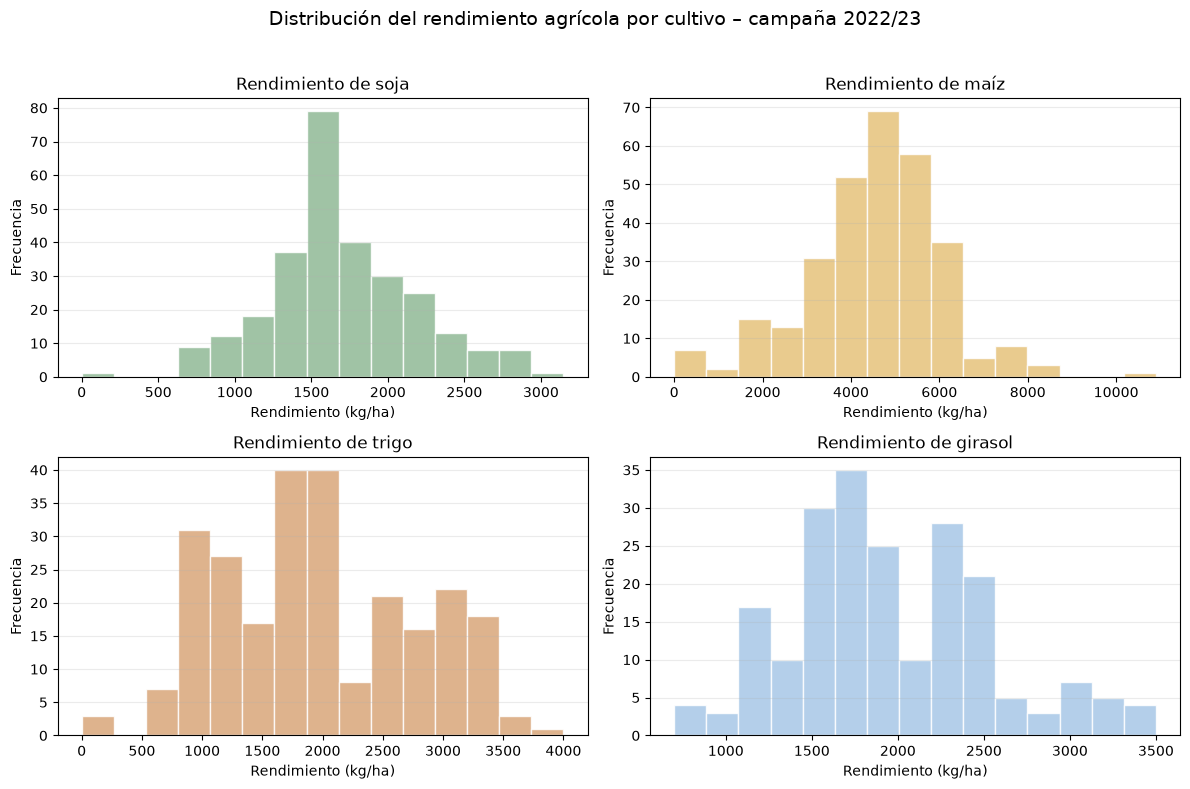

In [435]:
# Importar Matplotlib para construir los histogramas
import matplotlib.pyplot as plt

# Definir el orden, los colores y los títulos de los cultivos
orden_cultivos = ["soja", "maíz", "trigo", "girasol"]
colores_cultivos = ["#8FB996", "#E6C27A", "#D9A679", "#A7C7E7"]
titulos_cultivos = {
    "soja": "Rendimiento de soja",
    "maíz": "Rendimiento de maíz",
    "trigo": "Rendimiento de trigo",
    "girasol": "Rendimiento de girasol"
}

# Usar 15 intervalos para resumir la distribución con un nivel de detalle comparable
cantidad_bins = 15

# Crear una figura con cuatro subgráficos organizados en dos filas y dos columnas
figura, ejes = plt.subplots(2, 2, figsize=(12, 8))

# Recorrer cada cultivo y construir su histograma de rendimiento
for eje, cultivo, color in zip(ejes.flat, orden_cultivos, colores_cultivos):
    # Seleccionar únicamente las observaciones del cultivo actual
    registros_cultivo = df.loc[df["cultivo"] == cultivo, "rendimiento_kg_ha"]

    # Quitar solo los valores faltantes para graficar el rendimiento disponible
    # Los rendimientos iguales a cero se mantienen porque son observaciones válidas
    rendimiento_cultivo = registros_cultivo.dropna()

    # Construir el histograma; bins define la cantidad de intervalos del eje horizontal
    eje.hist(
        rendimiento_cultivo,
        bins=cantidad_bins,
        color=color,
        edgecolor="white",
        alpha=0.85
    )

    # Configurar títulos, ejes y una cuadrícula discreta para facilitar la lectura
    eje.set_title(titulos_cultivos[cultivo])
    eje.set_xlabel("Rendimiento (kg/ha)")
    eje.set_ylabel("Frecuencia")
    eje.grid(axis="y", alpha=0.25)

# Agregar un título general y ajustar la distribución de los subgráficos
figura.suptitle("Distribución del rendimiento agrícola por cultivo – campaña 2022/23", fontsize=14)
figura.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Interpretación de los histogramas

En soja, los rendimientos se concentran alrededor de valores cercanos a la mediana de 1.579,00 kg/ha. La media, de 1.692,13 kg/ha, es superior a la mediana, lo que resulta compatible con una distribución asimétrica hacia la derecha. El rendimiento máximo registrado es de 3.147,00 kg/ha.

En maíz, los rendimientos presentan valores generalmente superiores a los de los demás cultivos, con una media de 4.583,40 kg/ha y una mediana de 4.700,00 kg/ha. La distribución presenta una dispersión importante, con valores que van desde 0 hasta 10.900,00 kg/ha.

En trigo, la media es de 1.954,72 kg/ha y la mediana de 1.900,00 kg/ha, lo que indica que ambas medidas de tendencia central son relativamente próximas. Se identifican dos modas, de 1.800,00 y 2.000,00 kg/ha.

En girasol, la media de 1.951,39 kg/ha es ligeramente inferior a la mediana de 2.000,00 kg/ha. Los rendimientos observados se encuentran entre 700,00 y 3.500,00 kg/ha.

En conjunto, los histogramas permiten identificar diferencias en la distribución y dispersión de los rendimientos entre cultivos. El maíz presenta rendimientos superiores en términos absolutos, mientras que soja, trigo y girasol muestran valores centrales más próximos entre sí. Estas diferencias reflejan características de los datos observados y no implican, por sí solas, que un cultivo sea más eficiente o productivamente conveniente que otro.

### Diagramas de caja (boxplots)

Los diagramas de caja permiten visualizar y comparar la distribución de los rendimientos agrícolas, identificando su mediana, dispersión y posibles valores atípicos.

La caja representa el 50 % central de las observaciones, comprendido entre el primer cuartil (Q1) y el tercer cuartil (Q3). La línea interior indica la mediana (Q2). Los bigotes muestran los valores más extremos que se encuentran dentro de los límites establecidos por 1,5 veces el rango intercuartílico (RIC = Q3 − Q1).

Los puntos que quedan fuera de los bigotes se consideran posibles valores atípicos, aunque no necesariamente representan errores en los datos.

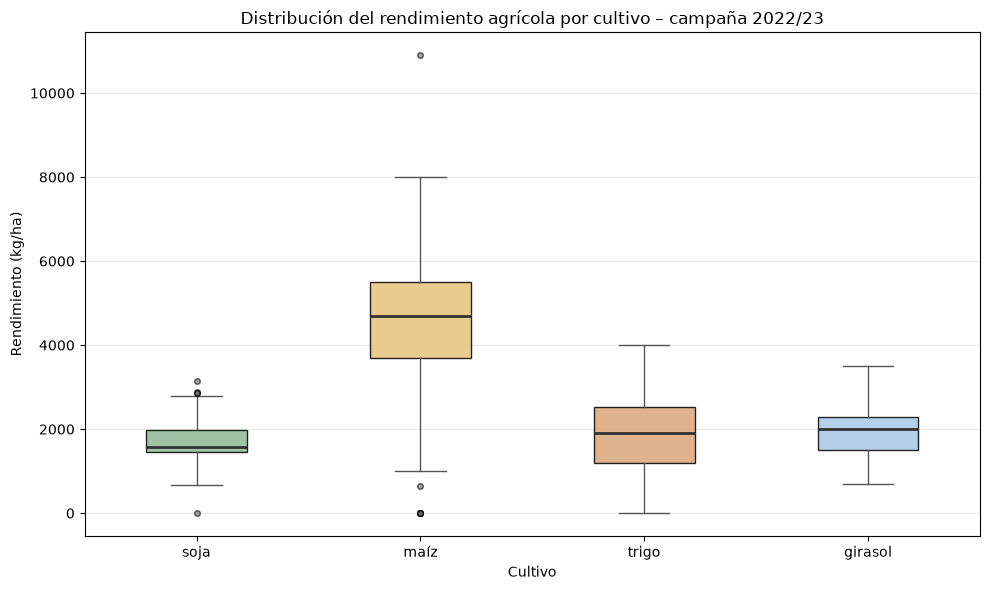

In [436]:
# Importar Matplotlib para construir el diagrama de caja
import matplotlib.pyplot as plt

# Definir el orden de los cultivos para facilitar la comparación visual
orden_cultivos_boxplot = ["soja", "maíz", "trigo", "girasol"]
colores_boxplot = ["#8FB996", "#E6C27A", "#D9A679", "#A7C7E7"]

# Seleccionar los rendimientos de cada cultivo sin modificar el DataFrame original
# Se eliminan únicamente los valores faltantes; los ceros se conservan
rendimientos_por_cultivo = [
    df.loc[df["cultivo"] == cultivo, "rendimiento_kg_ha"].dropna()
    for cultivo in orden_cultivos_boxplot
]

# Crear el gráfico comparativo de cajas
figura_boxplot, eje_boxplot = plt.subplots(figsize=(10, 6))
cajas = eje_boxplot.boxplot(
    rendimientos_por_cultivo,
    tick_labels=orden_cultivos_boxplot,
    patch_artist=True,
    showfliers=True,
    whis=1.5,
    medianprops={"color": "#333333", "linewidth": 2},
    whiskerprops={"color": "#555555"},
    capprops={"color": "#555555"},
    flierprops={"marker": "o", "markerfacecolor": "#666666", "markersize": 4, "alpha": 0.6}
)

# Aplicar colores suaves y consistentes a las cajas
for caja, color in zip(cajas["boxes"], colores_boxplot):
    caja.set_facecolor(color)
    caja.set_alpha(0.85)

# Configurar el título, los nombres de los ejes y la cuadrícula
eje_boxplot.set_title("Distribución del rendimiento agrícola por cultivo – campaña 2022/23")
eje_boxplot.set_xlabel("Cultivo")
eje_boxplot.set_ylabel("Rendimiento (kg/ha)")
eje_boxplot.grid(axis="y", alpha=0.25)

# Ajustar la presentación y mostrar el gráfico
figura_boxplot.tight_layout()
plt.show()

### Interpretación de los boxplots

El **maíz** presenta la mediana de rendimiento más elevada, con 4.700,00 kg/ha. Le siguen el girasol (2.000,00 kg/ha), el trigo (1.900,00 kg/ha) y la soja (1.579,00 kg/ha).

En cuanto a la dispersión, el maíz presenta el mayor rango intercuartílico (1.802,50 kg/ha), seguido por el trigo (1.321,00 kg/ha), el girasol (800,00 kg/ha) y la soja (536,00 kg/ha). Esto indica que los rendimientos de la mitad central de las observaciones están más dispersos en el maíz y más concentrados en la soja.

Además, se identifican posibles valores atípicos en soja y maíz, representados por puntos fuera de los bigotes. Estos valores corresponden a rendimientos alejados del conjunto central de observaciones y no necesariamente implican errores en los datos.

En conjunto, los boxplots permiten observar diferencias tanto en los rendimientos centrales como en su dispersión entre los cuatro cultivos.

### Gráficos de dispersión

Un gráfico de dispersión representa la relación entre dos variables cuantitativas mediante puntos. Cada punto corresponde a una observación de la base: en este caso, un registro de producción agrícola asociado a un cultivo y a un departamento o partido.

El eje horizontal mostrará la superficie cosechada en hectáreas y el eje vertical mostrará la producción en toneladas. La disposición de los puntos permite observar si existe una relación positiva, negativa o ausencia de relación lineal entre ambas variables.

Los valores extremos son observaciones que se encuentran alejadas del conjunto principal de puntos. Pueden influir en la forma visual de la relación y deben analizarse con cuidado, pero no necesariamente representan errores de carga. En primer lugar se observará la relación general diferenciando los cultivos por color y luego se analizará cada cultivo en un gráfico separado.

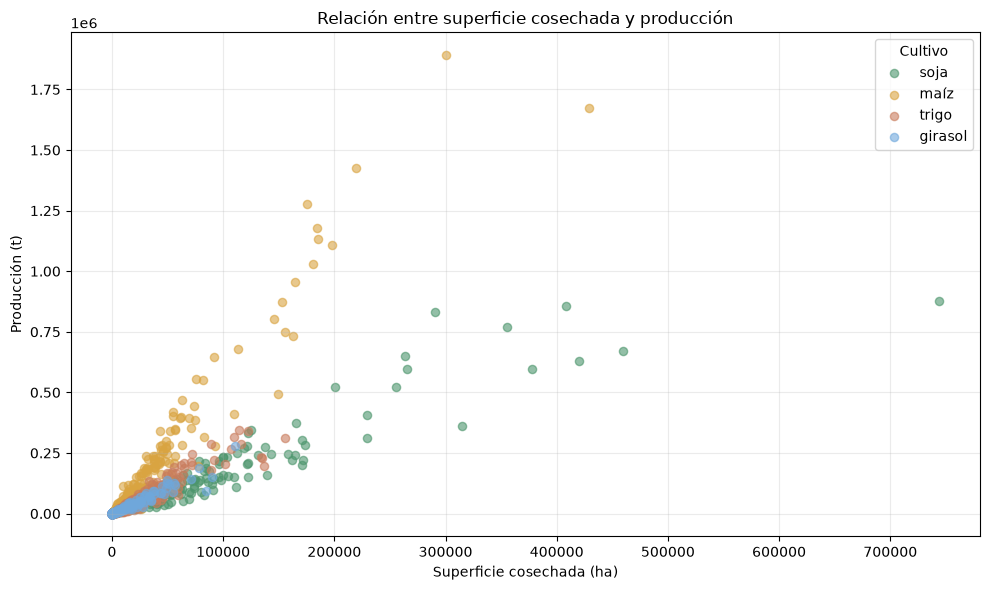

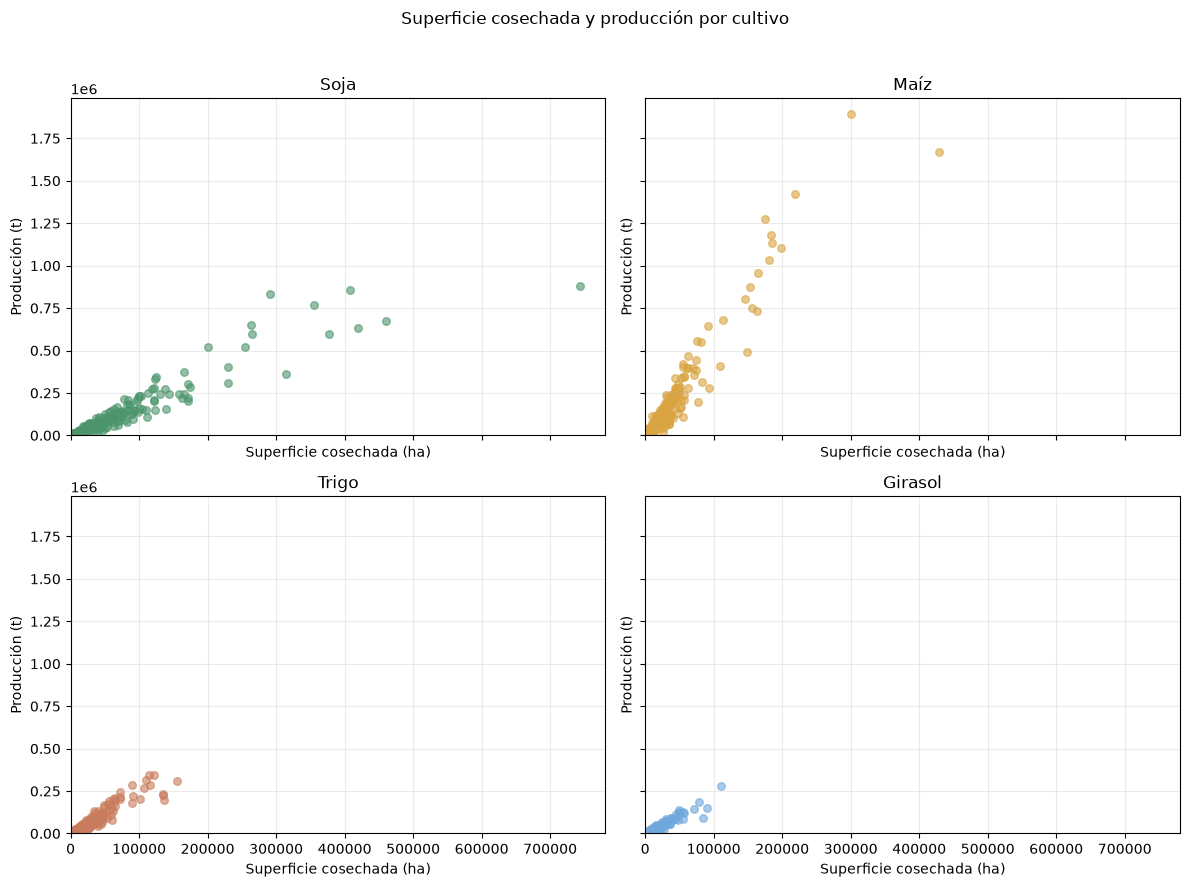

In [437]:
# Importar Matplotlib para construir los gráficos de dispersión
import matplotlib.pyplot as plt

# Seleccionar las variables necesarias sin modificar el DataFrame original
datos_dispersion = df[["superficie_cosechada_ha", "produccion_t", "cultivo"]].dropna()

# Definir el orden y los colores para diferenciar los cuatro cultivos
orden_cultivos_dispersion = ["soja", "maíz", "trigo", "girasol"]
colores_dispersion = {
    "soja": "#4C956C",
    "maíz": "#D9A441",
    "trigo": "#C97C5D",
    "girasol": "#6FA8DC"
}

# Crear el gráfico general de dispersión
figura_general, eje_general = plt.subplots(figsize=(10, 6))

# Graficar cada cultivo con un color diferente y transparencia para distinguir puntos superpuestos
for cultivo in orden_cultivos_dispersion:
    # Seleccionar los registros correspondientes al cultivo actual
    datos_cultivo = datos_dispersion[datos_dispersion["cultivo"] == cultivo]

    # Representar superficie cosechada en X y producción en Y
    eje_general.scatter(
        datos_cultivo["superficie_cosechada_ha"],
        datos_cultivo["produccion_t"],
        color=colores_dispersion[cultivo],
        alpha=0.60,
        s=35,
        label=cultivo
    )

# Configurar títulos, unidades de medida, leyenda y cuadrícula
eje_general.set_title("Relación entre superficie cosechada y producción")
eje_general.set_xlabel("Superficie cosechada (ha)")
eje_general.set_ylabel("Producción (t)")
eje_general.legend(title="Cultivo")
eje_general.grid(alpha=0.25)
figura_general.tight_layout()
plt.show()

# Crear una figura con cuatro gráficos separados, uno por cultivo
figura_cultivos, ejes_cultivos = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)

# Calcular límites comunes para facilitar la comparación entre los cuatro gráficos
limite_x = (0, datos_dispersion["superficie_cosechada_ha"].max() * 1.05)
limite_y = (0, datos_dispersion["produccion_t"].max() * 1.05)

# Construir el gráfico de dispersión correspondiente a cada cultivo
for eje, cultivo in zip(ejes_cultivos.flat, orden_cultivos_dispersion):
    # Seleccionar los registros del cultivo que se está representando
    datos_cultivo = datos_dispersion[datos_dispersion["cultivo"] == cultivo]

    # Usar la misma escala en todos los subgráficos y transparencia para reducir la superposición
    eje.scatter(
        datos_cultivo["superficie_cosechada_ha"],
        datos_cultivo["produccion_t"],
        color=colores_dispersion[cultivo],
        alpha=0.60,
        s=30
    )

    # Configurar el título y las unidades de los ejes de cada subgráfico
    eje.set_title(cultivo.capitalize())
    eje.set_xlabel("Superficie cosechada (ha)")
    eje.set_ylabel("Producción (t)")
    eje.set_xlim(limite_x)
    eje.set_ylim(limite_y)
    eje.grid(alpha=0.25)

# Aclarar que los cuatro subgráficos utilizan escalas comparables
figura_cultivos.suptitle("Superficie cosechada y producción por cultivo")
figura_cultivos.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Interpretación de los gráficos de dispersión

Los gráficos de dispersión permiten observar la relación entre la superficie cosechada (ha) y la producción (t) de los cuatro cultivos. En términos generales, se aprecia una asociación positiva: las observaciones con mayor superficie cosechada tienden a presentar una producción más elevada.

También se observan diferencias en la dispersión de los puntos entre cultivos y algunas observaciones de gran magnitud, que alcanzan 743.500 ha de superficie cosechada y 1.891.147 toneladas de producción.

En esta etapa no se calcula una correlación ni se ajusta una regresión, por lo que no se cuantifica la intensidad de la asociación ni se establece causalidad entre superficie cosechada y producción. La interpretación se limita, por lo tanto, a la descripción exploratoria de la relación visual.

### Síntesis del análisis exploratorio

El análisis de las 1.041 observaciones evidencia diferencias importantes en las superficies, la producción y los rendimientos agrícolas. Las superficies y la producción presentan distribuciones asimétricas hacia valores elevados. Entre los cultivos, el maíz registra el mayor rendimiento central y la mayor dispersión, mientras que soja, trigo y girasol presentan rendimientos centrales inferiores. Los gráficos de dispersión muestran una asociación positiva entre superficie cosechada y producción.

Los resultados son descriptivos y corresponden a promedios simples por departamento o partido. Además, se identificaron 22 valores faltantes en los rendimientos de la campaña anterior. Estas características deben considerarse al interpretar los resultados y realizar los análisis estadísticos posteriores.

# Punto 2 – IC y TH

En este punto se analizará el cambio del rendimiento de soja entre las campañas 2021/22 y 2022/23 en los mismos departamentos.

Los intervalos de confianza (IC) permiten estimar un parámetro poblacional a partir de los datos disponibles, estableciendo un rango de valores con un nivel de confianza determinado (95 % o 99 %).

Los tests de hipótesis (TH) permiten evaluar una afirmación estadística mediante dos hipótesis: la nula (H0) y la alternativa (H1). La decisión se toma comparando el valor p con el nivel de significación establecido (α = 0,05). Si el valor p es menor que α, se rechaza H0; en caso contrario, no se rechaza.

## Intervalos de confianza y test para la media

La variable numérica elegida será diferencia_rendimiento = rendimiento_2022_23 - rendimiento_2021_22, calculada para los mismos departamentos de soja con información válida en ambas campañas. Para su media se utilizará la distribución t de Student, porque la desviación estándar poblacional es desconocida. Un valor negativo indica que el rendimiento fue menor en 2022/23.

In [438]:
# Importar las herramientas estadísticas y numéricas necesarias
import numpy as np


# Seleccionar los pares válidos para que la variable analizada sea la diferencia entre campañas
soja_pares_p2 = df.loc[
    (df["cultivo"] == "soja")
    & df["rendimiento_kg_ha"].notna()
    & df["rendimiento_2021_22_kg_ha"].notna(),
    ["provincia", "region", "departamento", "rendimiento_kg_ha", "rendimiento_2021_22_kg_ha"]
].copy()

# Calcular 2022/23 menos 2021/22; los valores negativos indican caídas
soja_pares_p2["diferencia_rendimiento"] = soja_pares_p2["rendimiento_kg_ha"] - soja_pares_p2["rendimiento_2021_22_kg_ha"]
diferencias_rendimiento_p2 = soja_pares_p2["diferencia_rendimiento"]
n_diferencias_p2 = diferencias_rendimiento_p2.count()
media_diferencias_p2 = diferencias_rendimiento_p2.mean()
mediana_diferencias_p2 = diferencias_rendimiento_p2.median()
desviacion_diferencias_p2 = diferencias_rendimiento_p2.std(ddof=1)
cantidad_positivas_p2 = int((diferencias_rendimiento_p2 > 0).sum())
cantidad_negativas_p2 = int((diferencias_rendimiento_p2 < 0).sum())
cantidad_cero_p2 = int((diferencias_rendimiento_p2 == 0).sum())
grados_libertad_diferencias_p2 = n_diferencias_p2 - 1

# Resumir la magnitud y el sentido de las diferencias
tabla_descriptiva_diferencias_p2 = pd.DataFrame({
    "Observaciones válidas": [n_diferencias_p2],
    "Media de la diferencia (kg/ha)": [media_diferencias_p2],
    "Mediana (kg/ha)": [mediana_diferencias_p2],
    "Desviación estándar (kg/ha)": [desviacion_diferencias_p2],
    "Diferencias positivas": [cantidad_positivas_p2],
    "Diferencias negativas": [cantidad_negativas_p2],
    "Diferencias iguales a cero": [cantidad_cero_p2]
}).round(2)

# Calcular los IC bilaterales del 95 % y 99 % para la media de las diferencias
t_critico_95_p2 = stats.t.ppf(0.975, df=grados_libertad_diferencias_p2)
t_critico_99_p2 = stats.t.ppf(0.995, df=grados_libertad_diferencias_p2)
error_estandar_diferencias_p2 = desviacion_diferencias_p2 / np.sqrt(n_diferencias_p2)
ic_diferencias_95_p2 = (media_diferencias_p2 - t_critico_95_p2 * error_estandar_diferencias_p2, media_diferencias_p2 + t_critico_95_p2 * error_estandar_diferencias_p2)
ic_diferencias_99_p2 = (media_diferencias_p2 - t_critico_99_p2 * error_estandar_diferencias_p2, media_diferencias_p2 + t_critico_99_p2 * error_estandar_diferencias_p2)

# Presentar los intervalos junto con la distribución y los grados de libertad
tabla_intervalos_diferencias_p2 = pd.DataFrame({
    "Nivel de confianza": ["95%", "99%"],
    "Media de diferencias (kg/ha)": [media_diferencias_p2, media_diferencias_p2],
    "Límite inferior (kg/ha)": [ic_diferencias_95_p2[0], ic_diferencias_99_p2[0]],
    "Límite superior (kg/ha)": [ic_diferencias_95_p2[1], ic_diferencias_99_p2[1]],
    "Distribución": ["t de Student", "t de Student"],
    "Grados de libertad": [grados_libertad_diferencias_p2, grados_libertad_diferencias_p2]
})
tabla_intervalos_diferencias_p2[["Media de diferencias (kg/ha)", "Límite inferior (kg/ha)", "Límite superior (kg/ha)"]] = tabla_intervalos_diferencias_p2[["Media de diferencias (kg/ha)", "Límite inferior (kg/ha)", "Límite superior (kg/ha)"]].round(2)
display(tabla_descriptiva_diferencias_p2)
display(tabla_intervalos_diferencias_p2)

,Observaciones válidas,Media de la diferencia (kg/ha),Mediana (kg/ha),Desviación estándar (kg/ha),Diferencias positivas,Diferencias negativas,Diferencias iguales a cero
0,276,-739.01,-874.5,700.69,31,237,8


,Nivel de confianza,Media de diferencias (kg/ha),Límite inferior (kg/ha),Límite superior (kg/ha),Distribución,Grados de libertad
0,95%,-739.01,-822.04,-655.98,t de Student,275
1,99%,-739.01,-848.41,-629.61,t de Student,275


### Interpretación de los intervalos de confianza

A partir de 276 pares válidos de observaciones de soja, la diferencia media (2022/23 menos 2021/22) fue de -739,01 kg/ha. El intervalo de confianza del 95 % se extiende entre -822,04 y -655,98 kg/ha, mientras que el intervalo del 99 % abarca de -848,41 a -629,61 kg/ha. Como establece la teoría, al aumentar el nivel de confianza también aumenta la amplitud del intervalo.

Los intervalos estiman la media del cambio observado entre ambas campañas en los pares disponibles. El signo negativo indica un menor rendimiento en 2022/23. Dado que los datos corresponden a estimaciones agrícolas por departamento y no a una muestra aleatoria, los intervalos deben interpretarse con cautela y no generalizarse automáticamente a toda la producción nacional.

## Test t de una muestra para la media de las diferencias

Para alinear el contraste con los intervalos de confianza, se evaluará la media de `diferencia_rendimiento` utilizando exactamente los mismos 276 pares válidos. El valor de referencia es cero, porque representa ausencia de cambio medio entre campañas y se deriva directamente de la pregunta de investigación.

Las hipótesis son H₀: μD = 0 y H₁: μD ≠ 0. El contraste es bilateral y utiliza α = 0,05. El estadístico se obtiene con la distribución t de Student y 275 grados de libertad.

In [439]:
# Definir cero como referencia porque representa ausencia de cambio medio
valor_referencia_diferencias_p2 = 0.0
alfa_test_media = 0.05

# Aplicar el test t bilateral usando las mismas observaciones de los intervalos
resultado_t_diferencias_p2 = stats.ttest_1samp(
    diferencias_rendimiento_p2,
    popmean=valor_referencia_diferencias_p2
)
grados_libertad_una_muestra = grados_libertad_diferencias_p2
decision_t_una_muestra = (
    "Rechazar H0" if resultado_t_diferencias_p2.pvalue < alfa_test_media
    else "No rechazar H0"
)

# Presentar el resultado con el estadístico, los grados de libertad y el valor p
tabla_test_media_una_muestra = pd.DataFrame({
    "Media de diferencias (kg/ha)": [media_diferencias_p2],
    "Valor de referencia (kg/ha)": [valor_referencia_diferencias_p2],
    "Estadístico t": [resultado_t_diferencias_p2.statistic],
    "Grados de libertad": [grados_libertad_una_muestra],
    "Valor p bilateral": [resultado_t_diferencias_p2.pvalue],
    "Alfa": [alfa_test_media],
    "Decisión": [decision_t_una_muestra]
})
tabla_test_media_una_muestra[["Media de diferencias (kg/ha)", "Valor de referencia (kg/ha)", "Estadístico t"]] = tabla_test_media_una_muestra[["Media de diferencias (kg/ha)", "Valor de referencia (kg/ha)", "Estadístico t"]].round(4)
tabla_test_media_una_muestra["Valor p bilateral"] = tabla_test_media_una_muestra["Valor p bilateral"].map(lambda valor: f"{valor:.3e}")
tabla_test_media_una_muestra

,Media de diferencias (kg/ha),Valor de referencia (kg/ha),Estadístico t,Grados de libertad,Valor p bilateral,Alfa,Decisión
0,-739.0072,0.0,-17.5217,275,1.121e-46,0.05,Rechazar H0


### Interpretación del test t de una muestra

El test produjo t = -17,5217, con 275 grados de libertad y valor p ≈ 1,12 × 10⁻⁴⁶. Por lo tanto, con α = 0,05 se rechaza H₀: la evidencia es incompatible con una diferencia media igual a cero bajo el modelo t utilizado.

La decisión es coherente con el intervalo de confianza del 95 %, que va de -822,04 a -655,98 kg/ha y no contiene cero. En los pares disponibles, el resultado describe un menor rendimiento medio en 2022/23 respecto de 2021/22; no permite atribuir causalidad ni generalizar automáticamente a toda la producción argentina.

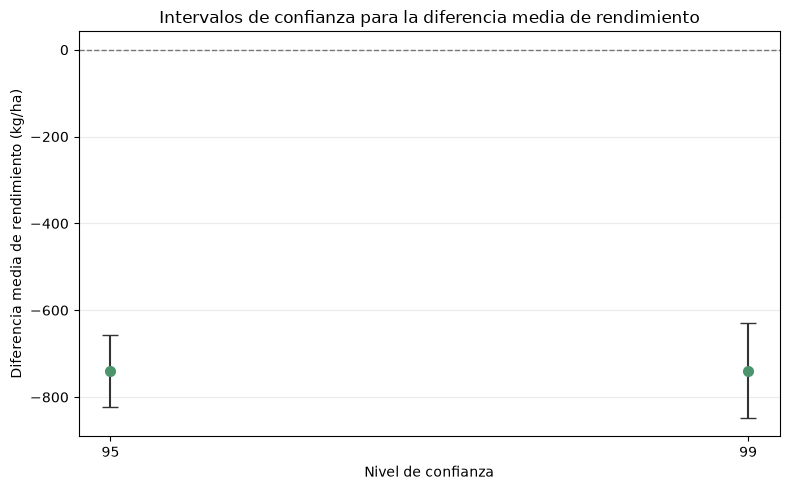

In [440]:
# Preparar los niveles de confianza y sus márgenes de error
niveles_confianza = [95, 99]
medias_ic = [media_diferencias_p2, media_diferencias_p2]
margenes_ic = [
    (ic_diferencias_95_p2[1] - ic_diferencias_95_p2[0]) / 2,
    (ic_diferencias_99_p2[1] - ic_diferencias_99_p2[0]) / 2
]

# Crear un gráfico de puntos con barras de error para los dos intervalos
figura_ic, eje_ic = plt.subplots(figsize=(8, 5))
eje_ic.errorbar(
    niveles_confianza,
    medias_ic,
    yerr=margenes_ic,
    fmt="o",
    color="#4C956C",
    ecolor="#333333",
    capsize=6,
    markersize=7
)

# Configurar títulos, ejes y unidades del gráfico
eje_ic.set_title("Intervalos de confianza para la diferencia media de rendimiento")
eje_ic.set_xlabel("Nivel de confianza")
eje_ic.set_ylabel("Diferencia media de rendimiento (kg/ha)")
eje_ic.axhline(0, color="#777777", linestyle="--", linewidth=1, label="Sin cambio")
eje_ic.set_xticks(niveles_confianza)
eje_ic.grid(axis="y", alpha=0.25)
figura_ic.tight_layout()
plt.show()

### Interpretación del gráfico de intervalos

El gráfico muestra la diferencia media estimada, acompañada por los intervalos de confianza del 95 % y 99 %. Ambos intervalos se ubican por debajo de cero, mientras que el intervalo del 99 % es más amplio por exigir un nivel de confianza mayor. La línea horizontal representa ausencia de cambio. Las barras de error comunican incertidumbre, pero no permiten por sí solas establecer causalidad ni resolver las limitaciones del diseño territorial.

In [441]:
# Comprobar que el contraste principal coincide con la formulación apareada
# Ambos procedimientos utilizan los mismos pares y la diferencia 2022/23 menos 2021/22
estadistico_apareado_complementario = media_diferencias_p2 / (desviacion_diferencias_p2 / np.sqrt(n_diferencias_p2))
valor_p_apareado_complementario = 2 * stats.t.sf(abs(estadistico_apareado_complementario), df=grados_libertad_diferencias_p2)
assert np.isclose(estadistico_apareado_complementario, resultado_t_diferencias_p2.statistic)
assert np.isclose(valor_p_apareado_complementario, resultado_t_diferencias_p2.pvalue)
print("Comprobación realizada: el test apareado coincide con el test de una muestra sobre las diferencias.")

Comprobación realizada: el test apareado coincide con el test de una muestra sobre las diferencias.


## Test de hipótesis para una proporción

Se construirá una variable dicotómica para las observaciones de soja con información válida en ambas campañas: toma el valor 1 si el rendimiento 2022/23 es menor que el de 2021/22 y 0 si es mayor o igual. El contraste utilizará 0,50 como referencia explícita: se evaluará si la proporción de observaciones con caída difiere de la mitad. Este valor no se interpreta como una proporción histórica conocida.

Para aproximar la distribución de la proporción muestral mediante una normal se verificarán las condiciones de éxito y fracaso esperados bajo H0. La hipótesis nula será H0: p = 0,50 y la alternativa H1: p ≠ 0,50.

In [442]:
# Seleccionar soja con rendimiento válido en las dos campañas
soja_proporcion = df.loc[
    (df["cultivo"] == "soja")
    & df["rendimiento_kg_ha"].notna()
    & df["rendimiento_2021_22_kg_ha"].notna(),
    ["rendimiento_kg_ha", "rendimiento_2021_22_kg_ha"]
].copy()

# Crear la variable dicotómica: 1 indica caída y 0 indica ausencia de caída
soja_proporcion["disminuyo"] = (
    soja_proporcion["rendimiento_kg_ha"]
    < soja_proporcion["rendimiento_2021_22_kg_ha"]
).astype(int)

# Calcular la cantidad y la proporción de observaciones con disminución
n_proporcion = len(soja_proporcion)
cantidad_disminuyo = soja_proporcion["disminuyo"].sum()
proporcion_disminuyo = cantidad_disminuyo / n_proporcion
cantidad_no_disminuyo = n_proporcion - cantidad_disminuyo
proporcion_no_disminuyo = cantidad_no_disminuyo / n_proporcion

# Definir la proporción de referencia y verificar las condiciones de aproximación normal
proporcion_referencia = 0.50
alfa_proporcion = 0.05
exitos_esperados = n_proporcion * proporcion_referencia
fracasos_esperados = n_proporcion * (1 - proporcion_referencia)
condiciones_proporcion = (exitos_esperados >= 10) and (fracasos_esperados >= 10)

# Calcular el estadístico z y el valor p bilateral del contraste de proporciones
error_estandar_proporcion = np.sqrt(
    proporcion_referencia * (1 - proporcion_referencia) / n_proporcion
)
estadistico_z = (proporcion_disminuyo - proporcion_referencia) / error_estandar_proporcion
valor_p_proporcion = 2 * stats.norm.sf(abs(estadistico_z))
decision_proporcion = (
    "Rechazar H0" if valor_p_proporcion < alfa_proporcion else "No rechazar H0"
)

# Presentar los resultados del análisis de la proporción
tabla_test_proporcion = pd.DataFrame({
    "Observaciones válidas": [n_proporcion],
    "Con disminución": [cantidad_disminuyo],
    "Sin disminución": [cantidad_no_disminuyo],
    "Proporción con disminución": [proporcion_disminuyo],
    "Proporción de referencia": [proporcion_referencia],
    "Éxitos esperados": [exitos_esperados],
    "Fracasos esperados": [fracasos_esperados],
    "Condiciones cumplidas": [condiciones_proporcion],
    "Estadístico z": [estadistico_z],
    "Valor p": [valor_p_proporcion],
    "Alfa": [alfa_proporcion],
    "Decisión": [decision_proporcion]
})
tabla_test_proporcion[["Proporción con disminución", "Proporción de referencia", "Estadístico z"]] = tabla_test_proporcion[["Proporción con disminución", "Proporción de referencia", "Estadístico z"]].round(4)
tabla_test_proporcion["Valor p"] = tabla_test_proporcion["Valor p"].map(lambda valor: f"{valor:.3e}")
tabla_test_proporcion

,Observaciones válidas,Con disminución,Sin disminución,Proporción con disminución,Proporción de referencia,Éxitos esperados,Fracasos esperados,Condiciones cumplidas,Estadístico z,Valor p,Alfa,Decisión
0,276,237,39,0.8587,0.5,138.0,138.0,True,11.9182,9.514e-33,0.05,Rechazar H0


### Interpretación del test de hipótesis para la proporción

La proporción se calculó únicamente sobre las observaciones de soja con rendimiento informado para ambas campañas. Se considera disminución cuando el rendimiento 2022/23 es estrictamente menor que el de 2021/22; los casos iguales se incluyen en la categoría sin disminución. De las 276 observaciones válidas, 237 presentaron disminución y 39 no la presentaron. La proporción de disminución fue 0,8587, equivalente al 85,87 %.

La decisión se obtiene comparando el valor p con α = 0,05. El estadístico fue z = 11,9182 y el valor p fue 9,514 × 10⁻³³, menor que α; por lo tanto, se rechaza H0: p = 0,50. La referencia 0,50 representa la mitad de las observaciones y no una proporción histórica conocida.

La inferencia debe interpretarse con cautela porque las observaciones provienen de estimaciones por departamento y no necesariamente constituyen una muestra aleatoria independiente.

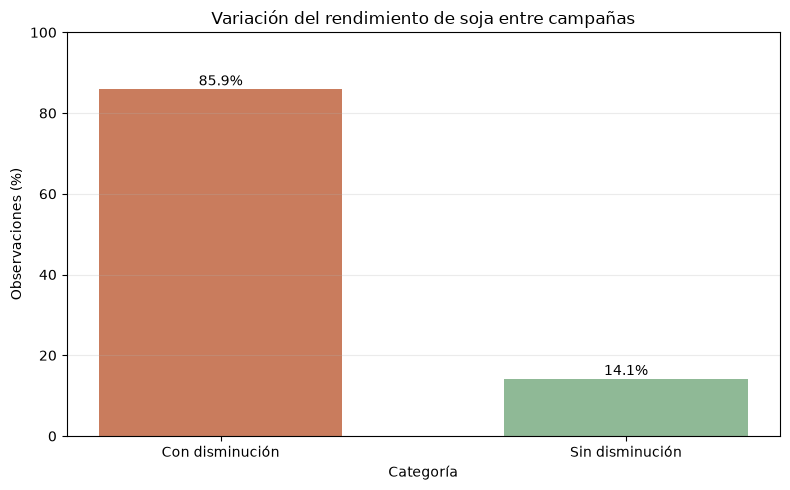

In [443]:
# Preparar las categorías y los porcentajes para el gráfico de barras
categorias_disminucion = ["Con disminución", "Sin disminución"]
porcentajes_disminucion = [
    proporcion_disminuyo * 100,
    proporcion_no_disminuyo * 100
]

# Crear un gráfico de barras para comunicar la proporción de cada categoría
figura_proporcion, eje_proporcion = plt.subplots(figsize=(8, 5))
barras = eje_proporcion.bar(
    categorias_disminucion,
    porcentajes_disminucion,
    color=["#C97C5D", "#8FB996"],
    width=0.6
)

# Configurar título, eje porcentual y límites de la escala
eje_proporcion.set_title("Variación del rendimiento de soja entre campañas")
eje_proporcion.set_xlabel("Categoría")
eje_proporcion.set_ylabel("Observaciones (%)")
eje_proporcion.set_ylim(0, 100)
eje_proporcion.grid(axis="y", alpha=0.25)

# Mostrar el porcentaje sobre cada barra
for barra, porcentaje in zip(barras, porcentajes_disminucion):
    eje_proporcion.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"{porcentaje:.1f}%",
        ha="center"
    )

# Ajustar la presentación y mostrar el gráfico
figura_proporcion.tight_layout()
plt.show()

### Interpretación del gráfico de proporciones

El gráfico de barras muestra que el 85,87 % de las observaciones válidas de soja presentó una disminución del rendimiento y que el 14,13 % no presentó disminución. La visualización complementa el test, cuyo resultado llevó a rechazar H0 frente a la referencia del 50 %. Los porcentajes corresponden únicamente a los pares con información válida y no deben generalizarse automáticamente a toda la producción agrícola argentina.

## Síntesis del Punto 2

En los pares válidos de soja, el rendimiento medio fue menor en 2022/23 que en 2021/22. Los intervalos de confianza y el test t son coherentes y respaldan evidencia de un cambio medio distinto de cero. Asimismo, la proporción de observaciones con caída fue mayor que la mitad y el contraste de proporciones rechazó la igualdad con 0,50. Estos resultados se refieren a los departamentos y campañas analizados; no establecen causalidad ni permiten generalizar automáticamente a toda la producción argentina.

# Punto 3 – Varianza y diferencias de media

En este punto se comparará el rendimiento de soja 2022/23 entre dos grupos territoriales: departamentos de la región Pampeana y departamentos de las demás regiones. La varianza mide la variabilidad de una variable respecto de su media y se expresa en unidades al cuadrado. Comparar varianzas permite estudiar si los grupos presentan diferente dispersión, mientras que comparar medias permite estudiar diferencias en su posición central.

El contraste F utiliza el cociente entre dos varianzas muestrales y requiere supuestos fuertes de normalidad e independencia. El estadístico t compara una diferencia de medias con su error estándar. En ambos casos, el valor p se interpretará como evidencia contra H0 cuando resulte menor que α = 0,05; no representa la probabilidad de que H0 sea verdadera.

Las observaciones son estimaciones agrícolas por departamento. Por lo tanto, la comparación se tratará como un análisis de dos grupos territoriales y no como dos muestras aleatorias independientes diseñadas específicamente para inferencia.

## Definición y verificación de los grupos

Se seleccionarán exclusivamente registros de soja. El Grupo A estará formado por observaciones de la región `Pampeana` y el Grupo B por observaciones de todas las demás regiones. Antes de calcular las estadísticas se verificarán las categorías observadas, el tamaño de cada grupo y los valores faltantes.

In [444]:
# Importar las herramientas estadísticas y numéricas necesarias
import numpy as np
from scipy import stats

# Seleccionar soja y conservar una copia para no modificar el DataFrame original
soja_regiones = df.loc[
    df["cultivo"] == "soja",
    ["region", "rendimiento_kg_ha"]
].copy()

# Crear la clasificación territorial solicitada
soja_regiones["grupo_territorial"] = np.where(
    soja_regiones["region"] == "Pampeana",
    "Pampeana",
    "Resto de regiones"
)

# Contar observaciones totales, observaciones de soja y faltantes por región
tabla_regiones = pd.DataFrame({
    "Observaciones totales": df.groupby("region").size(),
    "Observaciones de soja": df[df["cultivo"] == "soja"].groupby("region").size(),
    "Soja con rendimiento faltante": df[
        (df["cultivo"] == "soja")
        & df["rendimiento_kg_ha"].isna()
    ].groupby("region").size()
}).fillna(0).astype(int)

# Separar los dos grupos usando únicamente rendimientos no faltantes
soja_validos = soja_regiones.dropna(subset=["region", "rendimiento_kg_ha"])
rendimiento_pampeana = soja_validos.loc[
    soja_validos["grupo_territorial"] == "Pampeana",
    "rendimiento_kg_ha"
]
rendimiento_resto = soja_validos.loc[
    soja_validos["grupo_territorial"] == "Resto de regiones",
    "rendimiento_kg_ha"
]

# Mostrar las categorías observadas y los controles iniciales
print("Regiones observadas:", sorted(soja_regiones["region"].dropna().unique()))
print("Faltantes de rendimiento en soja:", soja_regiones["rendimiento_kg_ha"].isna().sum())
tabla_regiones

Regiones observadas: ['Cuyo', 'Noreste', 'Noroeste', 'Pampeana']
Faltantes de rendimiento en soja: 0


,Observaciones totales,Observaciones de soja,Soja con rendimiento faltante
region,,,
Cuyo,31,8,0
Noreste,143,41,0
Noroeste,200,65,0
Pampeana,667,167,0


### Interpretación de la definición de grupos

La tabla confirma las categorías regionales utilizadas y permite distinguir la región Pampeana del conjunto de las demás regiones. El análisis conserva los ceros de rendimiento como observaciones válidas y excluye únicamente los faltantes de `rendimiento_kg_ha` para calcular las estadísticas. Los dos grupos representan conjuntos territoriales de departamentos, por lo que la independencia y la representatividad aleatoria deben considerarse limitaciones del análisis.

In [445]:
# Organizar los rendimientos válidos en un diccionario para resumir ambos grupos
grupos_rendimiento = {
    "Pampeana": rendimiento_pampeana,
    "Resto de regiones": rendimiento_resto
}

# Calcular medidas descriptivas de rendimiento para cada grupo territorial
estadisticas_grupos = {}
for nombre_grupo, valores in grupos_rendimiento.items():
    estadisticas_grupos[nombre_grupo] = {
        "Observaciones válidas": valores.count(),
        "Media (kg/ha)": valores.mean(),
        "Mediana (kg/ha)": valores.median(),
        "Desviación estándar (kg/ha)": valores.std(ddof=1),
        "Varianza ((kg/ha)^2)": valores.var(ddof=1),
        "Mínimo (kg/ha)": valores.min(),
        "Máximo (kg/ha)": valores.max(),
        "Rango (kg/ha)": valores.max() - valores.min()
    }

# Convertir los resultados en una tabla comparativa
tabla_descriptiva_grupos = pd.DataFrame.from_dict(estadisticas_grupos, orient="index")
columnas_redondear_grupos = [
    "Media (kg/ha)", "Mediana (kg/ha)",
    "Desviación estándar (kg/ha)", "Varianza ((kg/ha)^2)",
    "Mínimo (kg/ha)", "Máximo (kg/ha)", "Rango (kg/ha)"
]
tabla_descriptiva_grupos[columnas_redondear_grupos] = tabla_descriptiva_grupos[columnas_redondear_grupos].round(2)
tabla_descriptiva_grupos

,Observaciones válidas,Media (kg/ha),Mediana (kg/ha),Desviación estándar (kg/ha),Varianza ((kg/ha)^2),Mínimo (kg/ha),Máximo (kg/ha),Rango (kg/ha)
Pampeana,167,1652.81,1576.0,475.52,226119.61,663,2866,2203
Resto de regiones,114,1749.73,1612.0,488.98,239101.12,0,3147,3147


### Interpretación de las estadísticas descriptivas

El rendimiento medio fue de 1.652,81 kg/ha en Pampeana y de 1.749,73 kg/ha en el resto; las medianas fueron 1.576 y 1.612 kg/ha, respectivamente. La desviación estándar fue de 475,52 kg/ha en Pampeana y 488,98 kg/ha en el resto, con varianzas muestrales de 226.119,61 y 239.101,12 (kg/ha)². Los rangos fueron 2.203 kg/ha y 3.147 kg/ha; el mínimo del resto fue 0 kg/ha y el máximo 3.147 kg/ha, mientras que Pampeana presentó mínimos y máximos de 663 y 2.866 kg/ha. Estas diferencias son descriptivas y todavía no permiten afirmar que las medias o varianzas poblacionales sean diferentes.

Las varianzas se expresan en `(kg/ha)^2`, mientras que las medias, medianas y medidas de rango se expresan en `kg/ha`. Por esa diferencia de unidades, la varianza se utiliza para comparar dispersión y no para interpretar directamente niveles de rendimiento.

In [446]:
# Revisar la forma de los grupos mediante asimetría y extremos observados
tabla_supuestos = pd.DataFrame({
    "Grupo": ["Pampeana", "Resto de regiones"],
    "Asimetría": [rendimiento_pampeana.skew(), rendimiento_resto.skew()],
    "Mínimo (kg/ha)": [rendimiento_pampeana.min(), rendimiento_resto.min()],
    "Máximo (kg/ha)": [rendimiento_pampeana.max(), rendimiento_resto.max()]
}).set_index("Grupo")

# Redondear la presentación de los diagnósticos descriptivos
tabla_supuestos = tabla_supuestos.round(4)
tabla_supuestos

,Asimetría,Mínimo (kg/ha),Máximo (kg/ha)
Grupo,,,
Pampeana,0.3159,663,2866
Resto de regiones,0.3088,0,3147


### Interpretación de los supuestos

La asimetría muestral fue moderada y positiva (0,316 y 0,309), pero también se observan extremos diferentes: Pampeana va de 663 a 2.866 kg/ha y el resto de 0 a 3.147 kg/ha. Como el contraste F depende especialmente de la normalidad e independencia para su distribución teórica, se informa como referencia condicionada y no como una inferencia plenamente válida.

En este análisis, los grupos corresponden a departamentos y pueden contener concentraciones territoriales y valores extremos. La falta de respaldo para los supuestos de normalidad e independencia limita la interpretación inferencial del test F.

In [447]:
# Obtener las varianzas muestrales de los dos grupos
varianza_pampeana = rendimiento_pampeana.var(ddof=1)
varianza_resto = rendimiento_resto.var(ddof=1)

# Construir el cociente usando la varianza mayor en el numerador
if varianza_pampeana >= varianza_resto:
    estadistico_f = varianza_pampeana / varianza_resto
    grados_libertad_f1 = len(rendimiento_pampeana) - 1
    grados_libertad_f2 = len(rendimiento_resto) - 1
    varianza_numerador = "Pampeana"
else:
    estadistico_f = varianza_resto / varianza_pampeana
    grados_libertad_f1 = len(rendimiento_resto) - 1
    grados_libertad_f2 = len(rendimiento_pampeana) - 1
    varianza_numerador = "Resto de regiones"

# Calcular el valor p bilateral del contraste F
p_f_cola_superior = stats.f.sf(estadistico_f, grados_libertad_f1, grados_libertad_f2)
p_f_cola_inferior = stats.f.cdf(estadistico_f, grados_libertad_f1, grados_libertad_f2)
valor_p_f = min(1, 2 * min(p_f_cola_superior, p_f_cola_inferior))
alfa_varianzas = 0.05
decision_f = "Rechazar H0" if valor_p_f < alfa_varianzas else "No rechazar H0"

# Resumir el resultado del contraste F de dos varianzas
tabla_varianzas = pd.DataFrame({
    "Procedimiento": ["F de dos varianzas"],
    "Hipótesis nula": ["σ²_Pampeana = σ²_Resto"],
    "Varianza Pampeana": [varianza_pampeana],
    "Varianza Resto": [varianza_resto],
    "Cociente / estadístico": [estadistico_f],
    "gl1": [grados_libertad_f1],
    "gl2": [grados_libertad_f2],
    "Valor p": [valor_p_f],
    "Decisión": [decision_f]
})
columnas_varianzas = ["Varianza Pampeana", "Varianza Resto", "Cociente / estadístico", "Valor p"]
tabla_varianzas[columnas_varianzas] = tabla_varianzas[columnas_varianzas].round(6)
tabla_varianzas

,Procedimiento,Hipótesis nula,Varianza Pampeana,Varianza Resto,Cociente / estadístico,gl1,gl2,Valor p,Decisión
0,F de dos varianzas,σ²_Pampeana = σ²_Resto,226119.613664,239101.12009,1.05741,113,166,0.737963,No rechazar H0


### Interpretación de la comparación de varianzas

El cociente F fue 1,0574, con gl1 = 113 y gl2 = 166, y valor p bilateral = 0,7380. Bajo los supuestos del modelo F, no se rechazaría H0 de igualdad de varianzas con α = 0,05. Sin embargo, la asimetría, los valores extremos y la posible dependencia territorial impiden tratar esta conclusión como plenamente válida.

El contraste se refiere únicamente a la variabilidad: no permite concluir igualdad de medias. Además, los grupos son territoriales y no fueron obtenidos mediante un muestreo aleatorio diseñado para este contraste.

In [448]:
# Calcular la diferencia de medias en el orden Pampeana menos Resto de regiones
media_pampeana = rendimiento_pampeana.mean()
media_resto = rendimiento_resto.mean()
diferencia_medias = media_pampeana - media_resto

# Aplicar el test t de Welch, que no supone igualdad de varianzas
resultado_welch = stats.ttest_ind(
    rendimiento_pampeana,
    rendimiento_resto,
    equal_var=False
)

# Calcular los grados de libertad aproximados de Welch
n_pampeana = len(rendimiento_pampeana)
n_resto = len(rendimiento_resto)
var_pampeana = rendimiento_pampeana.var(ddof=1)
var_resto = rendimiento_resto.var(ddof=1)
error_diferencia = np.sqrt(var_pampeana / n_pampeana + var_resto / n_resto)
grados_libertad_welch = (
    (var_pampeana / n_pampeana + var_resto / n_resto) ** 2
    / (
        (var_pampeana / n_pampeana) ** 2 / (n_pampeana - 1)
        + (var_resto / n_resto) ** 2 / (n_resto - 1)
    )
)

# Calcular el intervalo de confianza del 95 % para la diferencia de medias
t_critico_diferencia = stats.t.ppf(0.975, df=grados_libertad_welch)
ic_diferencia = (
    diferencia_medias - t_critico_diferencia * error_diferencia,
    diferencia_medias + t_critico_diferencia * error_diferencia
)

# Formular la decisión del test bilateral con alfa igual a 0,05
alfa_medias = 0.05
decision_medias = (
    "Rechazar H0" if resultado_welch.pvalue < alfa_medias else "No rechazar H0"
)

# Presentar el resultado del test de diferencia de medias
tabla_diferencia_medias = pd.DataFrame({
    "Media Pampeana (kg/ha)": [media_pampeana],
    "Media Resto (kg/ha)": [media_resto],
    "Diferencia Pampeana − Resto (kg/ha)": [diferencia_medias],
    "Estadístico t de Welch": [resultado_welch.statistic],
    "Grados de libertad": [grados_libertad_welch],
    "Valor p bilateral": [resultado_welch.pvalue],
    "IC 95% inferior (kg/ha)": [ic_diferencia[0]],
    "IC 95% superior (kg/ha)": [ic_diferencia[1]],
    "Decisión": [decision_medias]
})
columnas_medias = [
    "Media Pampeana (kg/ha)", "Media Resto (kg/ha)",
    "Diferencia Pampeana − Resto (kg/ha)", "Estadístico t de Welch",
    "Grados de libertad", "Valor p bilateral",
    "IC 95% inferior (kg/ha)", "IC 95% superior (kg/ha)"
]
tabla_diferencia_medias[columnas_medias] = tabla_diferencia_medias[columnas_medias].round(6)
tabla_diferencia_medias

,Media Pampeana (kg/ha),Media Resto (kg/ha),Diferencia Pampeana − Resto (kg/ha),Estadístico t de Welch,Grados de libertad,Valor p bilateral,IC 95% inferior (kg/ha),IC 95% superior (kg/ha),Decisión
0,1652.808383,1749.72807,-96.919687,-1.649739,238.368412,0.100314,-212.65226,18.812887,No rechazar H0


### Interpretación del test de diferencia de medias

Se utilizó el test t de Welch para comparar las medias de dos grupos independientes sin suponer igualdad de varianzas. La media de Pampeana fue 1.652,81 kg/ha y la del resto 1.749,73 kg/ha. La diferencia Pampeana - Resto fue -96,92 kg/ha. Welch no corrige por sí mismo problemas de normalidad ni de dependencia entre observaciones; solo modifica el error estándar y los grados de libertad frente a varianzas diferentes.

El estadístico fue t = -1,6497, con 238,37 grados de libertad aproximados, y valor p bilateral = 0,1003. El intervalo de confianza del 95 % para la diferencia fue [-212,65; 18,81] kg/ha, que contiene el cero. Por lo tanto, con α = 0,05 no se rechaza H0. Esto no demuestra que las medias sean exactamente iguales: indica que no se obtuvo evidencia suficiente de una diferencia distinta de cero bajo este procedimiento y con estas observaciones.

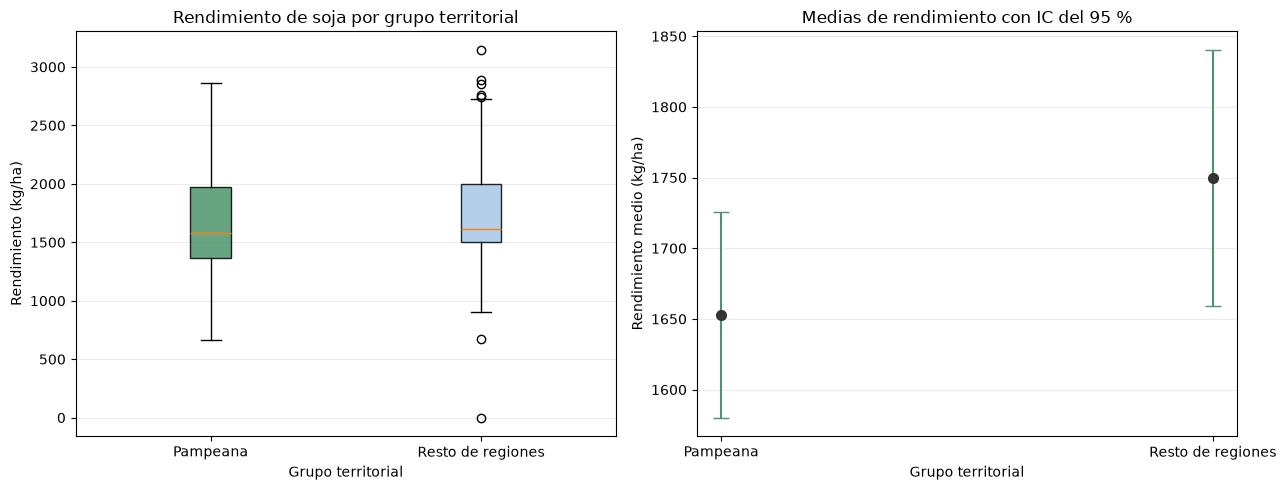

In [449]:
# Calcular intervalos individuales del 95 % para las medias de ambos grupos
muestras_graficos = [rendimiento_pampeana, rendimiento_resto]
nombres_graficos = ["Pampeana", "Resto de regiones"]
medias_graficos = [muestra.mean() for muestra in muestras_graficos]
intervalos_graficos = []
for muestra, media in zip(muestras_graficos, medias_graficos):
    error_estandar = muestra.std(ddof=1) / np.sqrt(len(muestra))
    valor_critico = stats.t.ppf(0.975, df=len(muestra) - 1)
    margen = valor_critico * error_estandar
    intervalos_graficos.append((media - margen, media + margen))

# Crear una figura con un boxplot y un gráfico de medias con intervalos
figura_punto3, (eje_cajas_p3, eje_medias_p3) = plt.subplots(1, 2, figsize=(13, 5))

# Mostrar la distribución completa y conservar posibles valores extremos
cajas_p3 = eje_cajas_p3.boxplot(
    muestras_graficos,
    tick_labels=nombres_graficos,
    patch_artist=True,
    showfliers=True,
    whis=1.5
)
for caja, color in zip(cajas_p3["boxes"], ["#4C956C", "#A7C7E7"]):
    caja.set_facecolor(color)
    caja.set_alpha(0.85)
eje_cajas_p3.set_title("Rendimiento de soja por grupo territorial")
eje_cajas_p3.set_xlabel("Grupo territorial")
eje_cajas_p3.set_ylabel("Rendimiento (kg/ha)")
eje_cajas_p3.grid(axis="y", alpha=0.25)

# Mostrar las medias como puntos y sus intervalos de confianza del 95 %
limites_inferiores = [media - intervalo[0] for media, intervalo in zip(medias_graficos, intervalos_graficos)]
limites_superiores = [intervalo[1] - media for media, intervalo in zip(medias_graficos, intervalos_graficos)]
eje_medias_p3.errorbar(
    nombres_graficos,
    medias_graficos,
    yerr=[limites_inferiores, limites_superiores],
    fmt="o",
    color="#333333",
    ecolor="#4C956C",
    capsize=6,
    markersize=7
)
eje_medias_p3.set_title("Medias de rendimiento con IC del 95 %")
eje_medias_p3.set_xlabel("Grupo territorial")
eje_medias_p3.set_ylabel("Rendimiento medio (kg/ha)")
eje_medias_p3.grid(axis="y", alpha=0.25)

# Ajustar la distribución de la figura y mostrar ambos gráficos
figura_punto3.tight_layout()
plt.show()

### Interpretación de los gráficos comparativos

El boxplot permite observar la mediana, la dispersión central y los posibles valores atípicos de cada grupo sin eliminar observaciones extremas. El gráfico de medias agrega los intervalos de confianza individuales del 95 %, facilitando la comparación de la incertidumbre de cada estimación.

El boxplot conserva todos los rendimientos y permite observar la mediana, el rango intercuartílico y los posibles valores extremos. El gráfico de medias muestra la diferencia descriptiva de aproximadamente 96,92 kg/ha entre grupos junto con intervalos individuales del 95 %. Estas visualizaciones deben leerse junto con el intervalo para la diferencia de medias, [-212,65; 18,81] kg/ha, y el valor p de Welch = 0,1003; la separación visual de intervalos individuales no constituye por sí sola una prueba de significación. Los posibles valores atípicos no se consideran automáticamente errores.

### Síntesis del Punto 3

Descriptivamente, Pampeana presentó un rendimiento medio algo menor que el resto y varianzas similares. El contraste F no rechazó la igualdad de varianzas y el test de Welch tampoco evidenció una diferencia de medias al 5 %. Esta conclusión está condicionada por el carácter territorial de los datos y por los supuestos de los procedimientos.

# Punto 4 – Diferencia de proporciones y ANOVA

En este punto se comparará, por un lado, la proporción de observaciones de soja con caída de rendimiento entre las campañas 2021/22 y 2022/23. Por otro lado, se analizará si el rendimiento medio de soja difiere entre provincias mediante un ANOVA de un factor.

La comparación de proporciones estudia una variable dicotómica entre dos grupos. El ANOVA compara medias de tres o más grupos mediante la relación entre la variabilidad entre grupos y la variabilidad dentro de los grupos. En ambos análisis, el valor p se interpretará junto con los supuestos y las limitaciones del diseño territorial de la base.


## Comparación de dos proporciones

Se utilizarán exclusivamente observaciones de soja con rendimiento válido en ambas campañas. La variable dicotómica toma el valor 1 cuando el rendimiento 2022/23 es menor que el de 2021/22 y el valor 0 en caso contrario. Se compararán la región Pampeana y el resto de las regiones.

La hipótesis nula es H0: p_Pampeana = p_Resto. La hipótesis alternativa es H1: p_Pampeana ≠ p_Resto. Se utilizará un contraste bilateral con α = 0,05. La aproximación normal se considerará únicamente si los recuentos esperados son suficientes.


In [450]:
# Importar las herramientas necesarias para el contraste de proporciones
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

# Crear una copia con soja y datos válidos de ambas campañas
soja_proporciones_p4 = df.loc[
    df["cultivo"].eq("soja"),
    ["region", "rendimiento_kg_ha", "rendimiento_2021_22_kg_ha"]
].dropna().copy()

# Formar los dos grupos territoriales sin modificar el DataFrame original
soja_proporciones_p4["grupo"] = np.where(
    soja_proporciones_p4["region"].eq("Pampeana"),
    "Pampeana",
    "Resto de regiones"
)
# Codificar la caída de rendimiento como una variable dicotómica
soja_proporciones_p4["caida_rendimiento"] = (
    soja_proporciones_p4["rendimiento_kg_ha"] < soja_proporciones_p4["rendimiento_2021_22_kg_ha"]
).astype(int)

# Resumir cantidad de observaciones, caídas y proporciones por grupo
tabla_proporciones_p4 = soja_proporciones_p4.groupby("grupo")["caida_rendimiento"].agg(observaciones_validas="count", observaciones_con_caida="sum", proporcion_caida="mean").reindex(["Pampeana", "Resto de regiones"])
tabla_proporciones_p4["porcentaje_caida"] = (tabla_proporciones_p4["proporcion_caida"] * 100).round(2)

# Obtener los recuentos observados y verificar la aproximación normal
recuentos = tabla_proporciones_p4["observaciones_con_caida"].to_numpy()
totales = tabla_proporciones_p4["observaciones_validas"].to_numpy()
proporcion_combinada = recuentos.sum() / totales.sum()
esperados_caida = totales * proporcion_combinada
esperados_no_caida = totales * (1 - proporcion_combinada)
condiciones_proporciones_p4 = bool(np.all(esperados_caida >= 5) and np.all(esperados_no_caida >= 5))

# Aplicar el test bilateral de diferencia de proporciones
estadistico_z_p4, valor_p_proporciones_p4 = proportions_ztest(recuentos, totales, alternative="two-sided")
alfa_p4 = 0.05
decision_proporciones_p4 = "Rechazar H0" if valor_p_proporciones_p4 < alfa_p4 else "No rechazar H0"

# Calcular la diferencia descriptiva entre las proporciones observadas
proporcion_pampeana_p4, proporcion_resto_p4 = tabla_proporciones_p4["proporcion_caida"]
diferencia_proporciones_p4 = proporcion_pampeana_p4 - proporcion_resto_p4
display(tabla_proporciones_p4)
print(f"Diferencia observada Pampeana − Resto: {diferencia_proporciones_p4:.4f}")


,observaciones_validas,observaciones_con_caida,proporcion_caida,porcentaje_caida
grupo,,,,
Pampeana,167,149,0.892216,89.22
Resto de regiones,109,88,0.807339,80.73


Diferencia observada Pampeana − Resto: 0.0849


### Interpretación de la comparación de proporciones

Se analizaron 167 observaciones válidas de Pampeana y 109 del resto. La caída se observó en 149 casos de Pampeana (89,22 %) y en 88 casos del resto (80,73 %). La diferencia observada fue de 0,0849, equivalente a 8,49 puntos porcentuales.

Los recuentos esperados superan 5, por lo que la aproximación normal resulta aplicable como referencia. El estadístico fue z = 1,9788 y el valor p bilateral fue 0,0478. Con α = 0,05 se rechaza H0 en este contraste, lo que indica evidencia estadística de una diferencia entre las proporciones observadas.

Estas proporciones describen las observaciones disponibles y no son probabilidades poblacionales conocidas. Además, los departamentos no constituyen necesariamente observaciones independientes obtenidas mediante muestreo aleatorio.


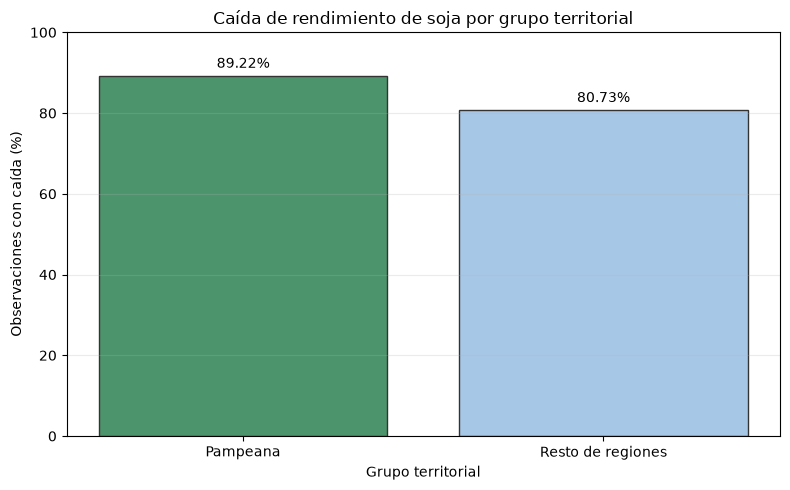

In [451]:
# Preparar los porcentajes observados para el gráfico comparativo
grupos_proporciones_p4 = tabla_proporciones_p4.index.tolist()
porcentajes_proporciones_p4 = tabla_proporciones_p4["porcentaje_caida"].tolist()
# Crear un gráfico de barras con el porcentaje de caídas por grupo
figura_proporciones_p4, eje_proporciones_p4 = plt.subplots(figsize=(8, 5))
barras_proporciones_p4 = eje_proporciones_p4.bar(
    grupos_proporciones_p4,
    porcentajes_proporciones_p4,
    color=["#4C956C", "#A7C7E7"],
    edgecolor="#333333"
)
# Configurar título, ejes, escala y etiquetas de porcentaje
eje_proporciones_p4.set_title("Caída de rendimiento de soja por grupo territorial")
eje_proporciones_p4.set_xlabel("Grupo territorial")
eje_proporciones_p4.set_ylabel("Observaciones con caída (%)")
eje_proporciones_p4.set_ylim(0, 100)
eje_proporciones_p4.grid(axis="y", alpha=0.25)
for barra, porcentaje in zip(barras_proporciones_p4, porcentajes_proporciones_p4):
    eje_proporciones_p4.text(barra.get_x() + barra.get_width() / 2, porcentaje + 2, f"{porcentaje:.2f}%", ha="center")
figura_proporciones_p4.tight_layout()
plt.show()


### Interpretación del gráfico de proporciones

El gráfico muestra una mayor proporción observada de caídas en Pampeana (89,22 %) que en el resto de las regiones (80,73 %), con una diferencia de 8,49 puntos porcentuales. La figura comunica la diferencia descriptiva; la decisión inferencial corresponde al contraste z y debe leerse junto con su intervalo de confianza y las limitaciones del diseño.

## Análisis de varianza – ANOVA

Se estudiará el rendimiento 2022/23 de soja entre provincias. Se incluirán las provincias con al menos 10 observaciones válidas, criterio fijado antes de observar los resultados inferenciales. La variabilidad entre grupos representa diferencias entre medias provinciales; la variabilidad dentro de los grupos representa la dispersión de los rendimientos alrededor de cada media.

La hipótesis nula es H0: todas las medias poblacionales son iguales. La alternativa es H1: al menos una media difiere. El estadístico F compara la variabilidad entre grupos con la variabilidad residual dentro de los grupos. La interpretación supone independencia, normalidad aproximada dentro de los grupos y varianzas homogéneas; estas condiciones se valorarán de forma descriptiva, sin incorporar pruebas adicionales al programa.


In [452]:
# Importar las herramientas para ajustar el modelo ANOVA de un factor
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Seleccionar soja con provincia y rendimiento válidos
soja_provincias_p4 = df.loc[
    df["cultivo"].eq("soja"), ["provincia", "rendimiento_kg_ha"]
].dropna().copy()

# Definir el criterio de inclusión antes del análisis inferencial
conteos_provincias_p4 = soja_provincias_p4["provincia"].value_counts().sort_index()
minimo_observaciones_p4 = 10
provincias_incluidas_p4 = conteos_provincias_p4[
    conteos_provincias_p4 >= minimo_observaciones_p4
].index.tolist()
provincias_excluidas_p4 = conteos_provincias_p4[
    conteos_provincias_p4 < minimo_observaciones_p4
]

# Formar la base del ANOVA con las provincias seleccionadas por tamaño muestral
datos_anova_p4 = soja_provincias_p4[
    soja_provincias_p4["provincia"].isin(provincias_incluidas_p4)
].copy()

# Calcular estadísticas descriptivas por provincia
tabla_descriptiva_provincias_p4 = (
    datos_anova_p4.groupby("provincia")["rendimiento_kg_ha"]
    .agg(observaciones="count", media_kg_ha="mean", mediana_kg_ha="median", desviacion_estandar_kg_ha=lambda x: x.std(ddof=1), varianza_kg_ha_2=lambda x: x.var(ddof=1))
    .reindex(provincias_incluidas_p4)
)
tabla_descriptiva_provincias_p4.iloc[:, 1:] = tabla_descriptiva_provincias_p4.iloc[:, 1:].round(2)
tabla_descriptiva_provincias_p4


,observaciones,media_kg_ha,mediana_kg_ha,desviacion_estandar_kg_ha,varianza_kg_ha_2
provincia,,,,,
Buenos Aires,97,1843.62,1737.0,421.88,177985.32
Chaco,18,1678.89,1817.0,477.19,227712.69
Córdoba,23,1445.39,1286.0,398.08,158468.07
Entre Ríos,16,1013.94,927.5,218.62,47793.00
La Pampa,12,1731.92,1767.5,303.38,92041.36
Salta,15,1591.93,1552.0,109.38,11964.35
Santa Fe,19,1417.79,1461.0,412.14,169858.40
Santiago del Estero,26,1960.54,1500.0,571.88,327051.30
Tucumán,14,1614.29,1500.0,231.57,53626.37


### Interpretación de las estadísticas descriptivas por provincia

El criterio de al menos 10 observaciones incluyó Buenos Aires, Chaco, Córdoba, Entre Ríos, La Pampa, Salta, Santa Fe, Santiago del Estero y Tucumán. Quedaron excluidas Misiones, Corrientes, San Luis, Jujuy, Formosa y Catamarca por no alcanzar el mínimo establecido.

Las medias muestran diferencias descriptivas: Entre Ríos presentó la menor media (1.013,94 kg/ha), mientras que Santiago del Estero presentó la mayor (1.960,54 kg/ha). Las dispersiones también son diferentes; por ejemplo, Santiago del Estero tuvo una desviación estándar de 571,88 kg/ha y Salta de 109,38 kg/ha. Estas diferencias descriptivas no determinan por sí solas significación estadística ni importancia productiva.


In [453]:
# Ajustar el modelo lineal de un factor para evaluar los supuestos y el ANOVA
modelo_anova_p4 = ols(
    "rendimiento_kg_ha ~ C(provincia)", data=datos_anova_p4
).fit()

# Obtener la tabla ANOVA clásica de un factor
tabla_anova_p4 = sm.stats.anova_lm(modelo_anova_p4, typ=2).reset_index()
tabla_anova_p4 = tabla_anova_p4.rename(columns={"index":"Fuente de variación", "sum_sq":"Suma de cuadrados", "df":"Grados de libertad", "F":"Estadístico F", "PR(>F)":"Valor p"})
tabla_anova_p4["Cuadrados medios"] = tabla_anova_p4["Suma de cuadrados"] / tabla_anova_p4["Grados de libertad"]
tabla_anova_p4 = tabla_anova_p4[["Fuente de variación", "Suma de cuadrados", "Grados de libertad", "Cuadrados medios", "Estadístico F", "Valor p"]]
tabla_anova_p4.iloc[:, 1:] = tabla_anova_p4.iloc[:, 1:].round(6)
tabla_anova_p4["Valor p"] = tabla_anova_p4["Valor p"].map(lambda valor: "<0,001" if pd.notna(valor) and valor < 0.001 else (f"{valor:.4f}" if pd.notna(valor) else ""))
tabla_anova_p4


,Fuente de variación,Suma de cuadrados,Grados de libertad,Cuadrados medios,Estadístico F,Valor p
0,C(provincia),1.452170e+07,8.0,1.815212e+06,10.956234,"<0,001"
1,Residual,3.827173e+07,231.0,1.656785e+05,NaN,


### Interpretación del ANOVA y sus supuestos

El ANOVA clásico produjo F(8, 231) = 10,9562 y valor p < 0,001, por lo que se rechaza H0 de igualdad conjunta de medias entre las provincias seleccionadas. El resultado indica que no todas las medias provinciales son iguales, pero el ANOVA global no identifica qué pares difieren.

La interpretación requiere cautela porque los tamaños de los grupos son desiguales, los rendimientos presentan dispersión y valores extremos, y la independencia territorial no está garantizada. Por ello, el ANOVA clásico se presenta como el procedimiento central solicitado, condicionado a sus supuestos y sin afirmar que las diferencias sean causales.

La consigna de este trabajo solicita la tabla ANOVA y su interpretación global; por eso no se incorporan comparaciones post hoc. Para conocer qué pares difieren sería necesario un análisis posterior específico, que excede el alcance adoptado aquí.


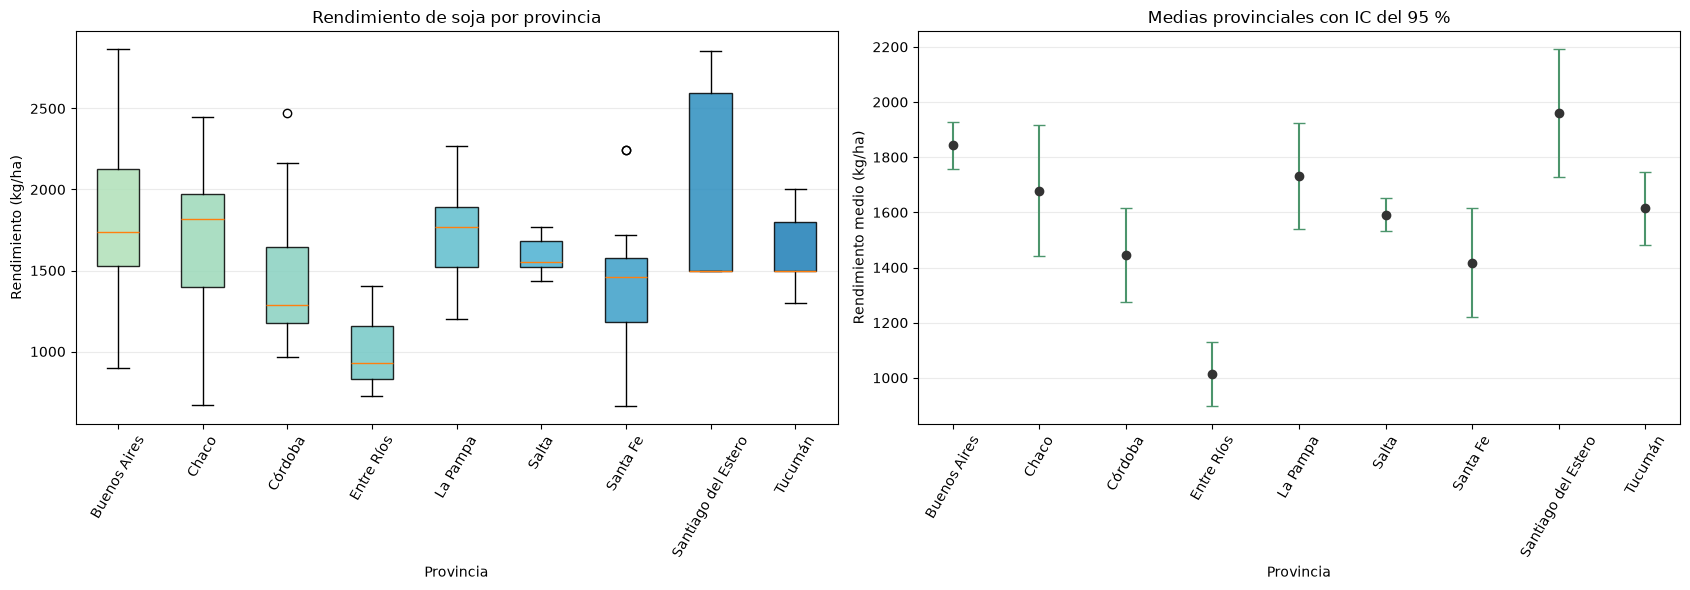

In [454]:
# Ordenar las provincias alfabéticamente para facilitar la lectura
orden_provincias_p4 = sorted(provincias_incluidas_p4)
muestras_ordenadas_p4 = [
    datos_anova_p4.loc[
        datos_anova_p4["provincia"].eq(provincia), "rendimiento_kg_ha"
    ]
    for provincia in orden_provincias_p4
]

# Calcular medias e intervalos individuales del 95 % para el gráfico
medias_provincias_p4 = [muestra.mean() for muestra in muestras_ordenadas_p4]
errores_provincias_p4 = []
for muestra, media in zip(muestras_ordenadas_p4, medias_provincias_p4):
    error_estandar = muestra.std(ddof=1) / np.sqrt(len(muestra))
    margen = stats.t.ppf(0.975, len(muestra) - 1) * error_estandar
    errores_provincias_p4.append(margen)

# Crear un boxplot y un gráfico de medias con intervalos de confianza
figura_anova_p4, (eje_boxplot_anova_p4, eje_medias_anova_p4) = plt.subplots(
    1, 2, figsize=(17, 6)
)
cajas_anova_p4 = eje_boxplot_anova_p4.boxplot(muestras_ordenadas_p4, tick_labels=orden_provincias_p4, patch_artist=True, showfliers=True, whis=1.5)
for caja, color in zip(cajas_anova_p4["boxes"], plt.cm.GnBu(np.linspace(0.35, 0.8, len(orden_provincias_p4)))):
    caja.set_facecolor(color)
    caja.set_alpha(0.85)
eje_boxplot_anova_p4.set_title("Rendimiento de soja por provincia")
eje_boxplot_anova_p4.set_xlabel("Provincia")
eje_boxplot_anova_p4.set_ylabel("Rendimiento (kg/ha)")
eje_boxplot_anova_p4.tick_params(axis="x", rotation=60)
eje_boxplot_anova_p4.grid(axis="y", alpha=0.25)

# Mostrar las medias provinciales con intervalos individuales del 95 %
eje_medias_anova_p4.errorbar(orden_provincias_p4, medias_provincias_p4, yerr=errores_provincias_p4, fmt="o", color="#333333", ecolor="#4C956C", capsize=4)
eje_medias_anova_p4.set_title("Medias provinciales con IC del 95 %")
eje_medias_anova_p4.set_xlabel("Provincia")
eje_medias_anova_p4.set_ylabel("Rendimiento medio (kg/ha)")
eje_medias_anova_p4.tick_params(axis="x", rotation=60)
eje_medias_anova_p4.grid(axis="y", alpha=0.25)
figura_anova_p4.tight_layout()
plt.show()


### Interpretación de los gráficos del ANOVA

El boxplot permite comparar medianas, rangos intercuartílicos, dispersión y posibles valores extremos entre las provincias incluidas. El gráfico de medias muestra las diferencias de nivel y la incertidumbre individual de cada media mediante intervalos del 95 %. La variabilidad visible es consistente con los resultados descriptivos de las provincias.

Los gráficos ayudan a localizar qué grupos presentan mayores diferencias descriptivas, pero no reemplazan el ANOVA ni las comparaciones posteriores. Los puntos extremos se conservaron y no deben interpretarse automáticamente como errores de carga.


### Síntesis del Punto 4

La proporción de caídas fue mayor en Pampeana que en el resto y el contraste rechazó la igualdad al 5 %. En las nueve provincias seleccionadas, el ANOVA mostró diferencias entre medias de rendimiento. Ambos resultados deben interpretarse como comparaciones acotadas por los tamaños desiguales y la posible dependencia territorial.


# Punto 5 – Regresión y correlación

Se analizará la relación entre la superficie cosechada y la producción de soja durante la campaña 2022/23. La superficie cosechada será la variable independiente X y la producción la variable dependiente Y.

La correlación describirá la dirección y la intensidad de la asociación lineal. La regresión lineal simple estimará una recta que relacione ambas variables. Estos resultados son descriptivos y no deben interpretarse automáticamente como evidencia de causalidad, especialmente porque producción, superficie y rendimiento están vinculados por una identidad productiva.


## Exploración de la relación

En un gráfico de dispersión, cada punto representa una observación agrícola de soja. El eje horizontal muestra la superficie cosechada en hectáreas y el eje vertical la producción en toneladas. Una nube ascendente sugiere una asociación positiva; una nube descendente, una asociación negativa. La linealidad se evalúa observando si los puntos siguen aproximadamente una trayectoria recta.

Antes de calcular la correlación y ajustar la regresión se verifican los valores faltantes, los ceros y las observaciones extremas. Los puntos extremos pueden influir considerablemente en la recta y en el coeficiente de correlación.


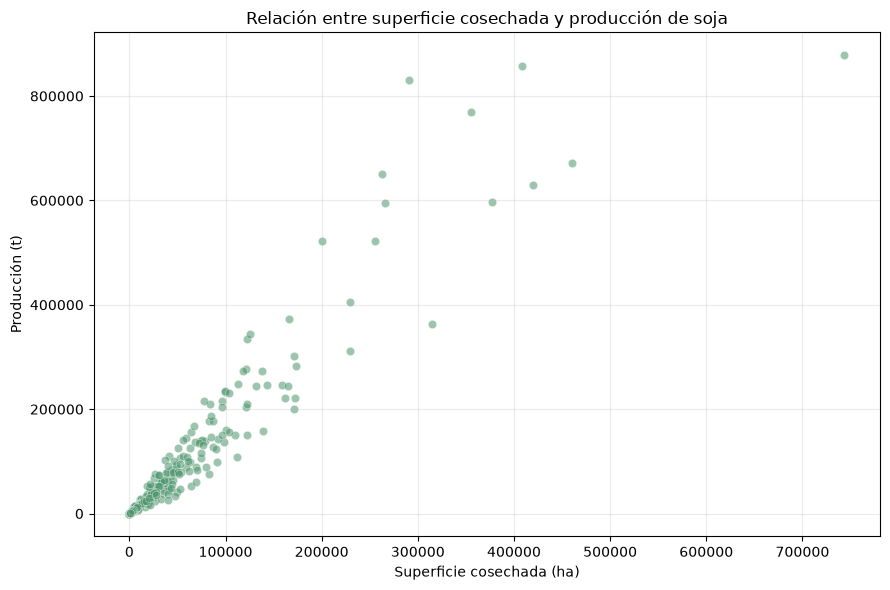

In [455]:
# Importar las herramientas gráficas y estadísticas necesarias
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
from scipy import stats

# Seleccionar únicamente soja y las dos variables del análisis
soja_relacion_p5 = df.loc[
    df["cultivo"].eq("soja"),
    ["superficie_cosechada_ha", "produccion_t"]
].copy()

# Excluir solo del análisis los registros con datos faltantes
soja_relacion_valida_p5 = soja_relacion_p5.dropna().copy()
cantidad_validas_p5 = len(soja_relacion_valida_p5)
faltantes_p5 = soja_relacion_p5.isna().sum()
ceros_p5 = (soja_relacion_valida_p5 == 0).sum()

# Crear el gráfico de dispersión sin modificar el DataFrame original
figura_dispersion_p5, eje_dispersion_p5 = plt.subplots(figsize=(9, 6))
eje_dispersion_p5.scatter(
    soja_relacion_valida_p5["superficie_cosechada_ha"],
    soja_relacion_valida_p5["produccion_t"],
    color="#4C956C",
    alpha=0.55,
    edgecolor="white",
    linewidth=0.4
)
eje_dispersion_p5.set_title("Relación entre superficie cosechada y producción de soja")
eje_dispersion_p5.set_xlabel("Superficie cosechada (ha)")
eje_dispersion_p5.set_ylabel("Producción (t)")
eje_dispersion_p5.grid(alpha=0.25)
figura_dispersion_p5.tight_layout()
plt.show()


### Interpretación del gráfico de dispersión

La nube de puntos muestra una asociación positiva y aproximadamente creciente: las observaciones con mayor superficie cosechada tienden a presentar mayor producción. La dispersión no es perfectamente constante a lo largo del eje horizontal y se observan puntos extremos, por lo que la relación debe evaluarse junto con los diagnósticos del modelo.

El análisis utiliza 281 observaciones válidas. No se detectaron valores faltantes en las dos variables; se conservó un registro con superficie cosechada igual a cero y uno con producción igual a cero. La relación visual no demuestra causalidad: ambas variables forman parte de la misma estructura productiva.


## Correlación de Pearson

El coeficiente de Pearson mide la dirección y la intensidad de la asociación lineal entre dos variables. Toma valores entre -1 y 1: el signo indica la dirección y el valor absoluto indica qué tan próxima es la asociación a una relación lineal perfecta. La correlación no implica causalidad y puede verse afectada por observaciones extremas.


In [456]:
# Calcular el coeficiente de Pearson y su valor p bilateral
resultado_pearson_p5 = stats.pearsonr(
    soja_relacion_valida_p5["superficie_cosechada_ha"],
    soja_relacion_valida_p5["produccion_t"]
)

# Presentar la cantidad de observaciones y el resultado del contraste
tabla_correlacion_p5 = pd.DataFrame({
    "Observaciones válidas": [cantidad_validas_p5],
    "Coeficiente r de Pearson": [resultado_pearson_p5.statistic],
    "Valor p bilateral": [resultado_pearson_p5.pvalue]
})
tabla_correlacion_p5 = tabla_correlacion_p5.round(6)
tabla_correlacion_p5


,Observaciones válidas,Coeficiente r de Pearson,Valor p bilateral
0,281,0.945026,0.0


### Interpretación de la correlación

El coeficiente de Pearson fue r = 0,9450, positivo y próximo a 1. Según el criterio descriptivo de proximidad al valor absoluto 1, la asociación lineal observada es alta. El contraste bilateral produjo p < 0,001, por lo que, bajo los supuestos del procedimiento, existe evidencia estadística de asociación lineal distinta de cero.

La magnitud del coeficiente puede estar influida por la identidad productiva entre superficie, producción y rendimiento, así como por observaciones extremas. Por eso no se interpreta como un efecto causal ni como una relación válida automáticamente fuera del rango observado.


## Regresión lineal simple

La regresión lineal simple estima la producción media asociada con distintos valores de superficie cosechada mediante la ecuación Y = β0 + β1X + error. La pendiente β1 representa el cambio promedio estimado en toneladas por cada hectárea adicional de superficie cosechada. El intercepto β0 es la producción estimada cuando la superficie es cero, aunque su interpretación productiva debe evaluarse dentro del rango observado.

Los coeficientes se estiman por mínimos cuadrados ordinarios, eligiendo la recta que minimiza la suma de los cuadrados de los residuos. R² expresa la proporción de variabilidad muestral de la producción explicada por la recta ajustada.


In [457]:
# Definir la superficie como variable independiente y agregar el intercepto
variable_x_p5 = sm.add_constant(soja_relacion_valida_p5["superficie_cosechada_ha"])
variable_y_p5 = soja_relacion_valida_p5["produccion_t"]

# Ajustar la regresión lineal simple por mínimos cuadrados ordinarios
modelo_regresion_p5 = sm.OLS(variable_y_p5, variable_x_p5).fit()

# Obtener los coeficientes, errores estándar, pruebas t e intervalos de confianza
tabla_regresion_p5 = pd.DataFrame({
    "Coeficiente": ["Intercepto", "Superficie cosechada"],
    "Estimación": modelo_regresion_p5.params.to_numpy(),
    "Error estándar": modelo_regresion_p5.bse.to_numpy(),
    "Estadístico t": modelo_regresion_p5.tvalues.to_numpy(),
    "Valor p": modelo_regresion_p5.pvalues.to_numpy(),
    "IC 95% inferior": modelo_regresion_p5.conf_int()[0].to_numpy(),
    "IC 95% superior": modelo_regresion_p5.conf_int()[1].to_numpy()
})
tabla_regresion_p5 = tabla_regresion_p5.round(6)
tabla_regresion_p5["Valor p"] = tabla_regresion_p5["Valor p"].map(lambda valor: "<0,001" if valor < 0.001 else f"{valor:.4f}")
r_cuadrado_p5 = modelo_regresion_p5.rsquared
intercepto_p5 = modelo_regresion_p5.params["const"]
pendiente_p5 = modelo_regresion_p5.params["superficie_cosechada_ha"]
ecuacion_p5 = f"Producción estimada = {intercepto_p5:.2f} + {pendiente_p5:.4f} × superficie cosechada"
tabla_regresion_p5, ecuacion_p5, r_cuadrado_p5


(            Coeficiente  Estimación  Error estándar  Estadístico t Valor p  \
 0            Intercepto  4789.57275     3370.167807       1.421167  0.1564   
 1  Superficie cosechada     1.65071        0.034195      48.273227  <0,001   
 
    IC 95% inferior  IC 95% superior  
 0     -1844.613116     11423.758616  
 1         1.583396         1.718023  ,
 'Producción estimada = 4789.57 + 1.6507 × superficie cosechada',
 np.float64(0.8930749537248336))

### Interpretación de la regresión lineal

La ecuación estimada es Producción = 4.789,57 + 1,6507 × superficie cosechada, con producción en toneladas y superficie en hectáreas. La pendiente indica que, dentro de los datos observados, una hectárea adicional de superficie cosechada se asocia en promedio con aproximadamente 1,6507 toneladas adicionales de producción. No representa un efecto causal demostrado ni un rendimiento medio nacional ponderado.

El intercepto estimado es 4.789,57 toneladas. Como la superficie igual a cero se encuentra en el extremo del rango observado y no describe necesariamente una situación productiva real, su interpretación debe tomarse con cautela. El modelo obtuvo R² = 0,8931: la recta explica el 89,31 % de la variabilidad muestral de la producción, sin garantizar predicciones adecuadas fuera del rango analizado.


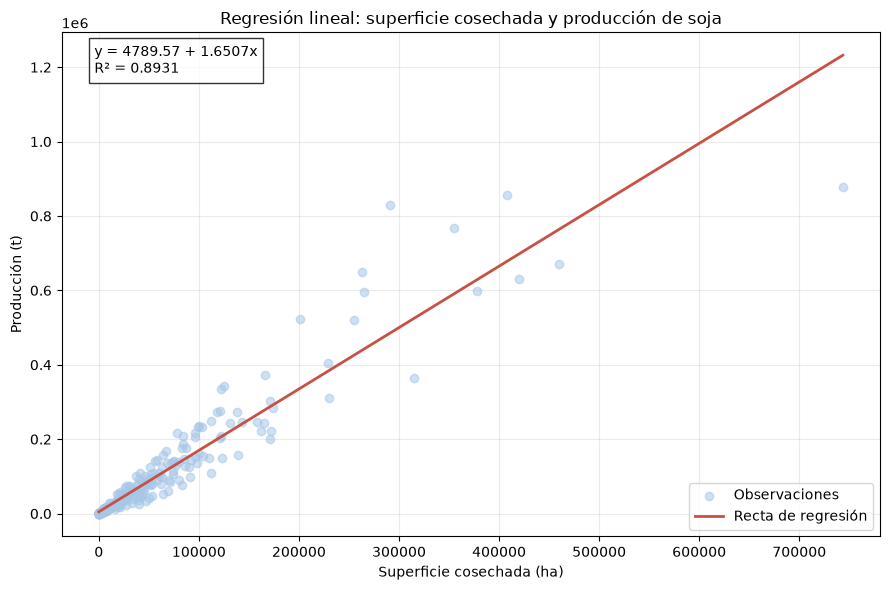

In [458]:
# Ordenar la superficie antes de dibujar la recta estimada
superficie_ordenada_p5 = np.sort(soja_relacion_valida_p5["superficie_cosechada_ha"].to_numpy())
superficie_con_constante_p5 = sm.add_constant(superficie_ordenada_p5)
produccion_estimada_p5 = modelo_regresion_p5.predict(superficie_con_constante_p5)

# Crear el gráfico con las observaciones y la recta de regresión
figura_regresion_p5, eje_regresion_p5 = plt.subplots(figsize=(9, 6))
eje_regresion_p5.scatter(
    soja_relacion_valida_p5["superficie_cosechada_ha"],
    soja_relacion_valida_p5["produccion_t"],
    color="#A7C7E7",
    alpha=0.55,
    label="Observaciones"
)
eje_regresion_p5.plot(
    superficie_ordenada_p5,
    produccion_estimada_p5,
    color="#C75146",
    linewidth=2,
    label="Recta de regresión"
)
eje_regresion_p5.set_title("Regresión lineal: superficie cosechada y producción de soja")
eje_regresion_p5.set_xlabel("Superficie cosechada (ha)")
eje_regresion_p5.set_ylabel("Producción (t)")
eje_regresion_p5.text(
    0.04, 0.92,
    f"y = {intercepto_p5:.2f} + {pendiente_p5:.4f}x\nR² = {r_cuadrado_p5:.4f}",
    transform=eje_regresion_p5.transAxes,
    bbox={"facecolor": "white", "alpha": 0.8}
)
eje_regresion_p5.legend()
eje_regresion_p5.grid(alpha=0.25)
figura_regresion_p5.tight_layout()
plt.show()


### Interpretación del gráfico de regresión

La recta acompaña la tendencia ascendente de la nube de puntos y resume la asociación lineal estimada. Las observaciones se mantienen dentro del rango de superficies realmente observado; no se representan extrapolaciones fuera de ese intervalo.

La concentración de puntos alrededor de la recta no es uniforme y existen observaciones alejadas, especialmente en superficies grandes. Por ello, el R² elevado debe interpretarse junto con el análisis de residuos y de influencia, no como garantía de un modelo causal o universal.


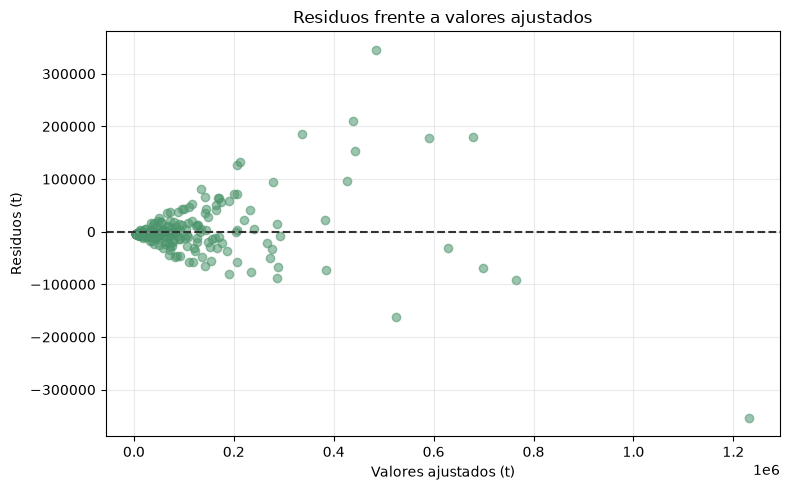

La dispersión de los residuos se revisa gráficamente alrededor de cero.


In [459]:
# Obtener los valores ajustados y los residuos del modelo
valores_ajustados_p5 = modelo_regresion_p5.fittedvalues
residuos_p5 = modelo_regresion_p5.resid
# Graficar los residuos frente a los valores ajustados
figura_diagnosticos_p5, eje_residuos_p5 = plt.subplots(figsize=(8, 5))
eje_residuos_p5.scatter(valores_ajustados_p5, residuos_p5, color="#4C956C", alpha=0.55)
eje_residuos_p5.axhline(0, color="#333333", linestyle="--")
eje_residuos_p5.set_title("Residuos frente a valores ajustados")
eje_residuos_p5.set_xlabel("Valores ajustados (t)")
eje_residuos_p5.set_ylabel("Residuos (t)")
eje_residuos_p5.grid(alpha=0.25)
figura_diagnosticos_p5.tight_layout()
plt.show()
print("La dispersión de los residuos se revisa gráficamente alrededor de cero.")

### Interpretación de los diagnósticos del modelo

El gráfico de residuos frente a los valores ajustados permite revisar visualmente si la dispersión se mantiene aproximadamente constante alrededor de cero. En este caso se observan valores extremos y una dispersión que no es completamente uniforme, por lo que la interpretación de la recta debe mantenerse dentro del rango observado.

La presencia de observaciones con superficies y producciones muy grandes puede influir visualmente en la recta ajustada. No se eliminan porque forman parte de la base y pueden representar situaciones agrícolas reales.

La independencia tampoco puede darse por garantizada, porque los registros corresponden a departamentos y pueden presentar dependencia territorial.


### Síntesis del Punto 5

La superficie cosechada y la producción presentaron una asociación lineal positiva y alta, y la recta explicó gran parte de la variabilidad observada dentro del rango analizado. La dispersión no uniforme de los residuos y los valores extremos requieren cautela; la relación no implica causalidad ni habilita extrapolaciones fuera del rango disponible.


# Punto 6 – Test Chi-cuadrado

Se analizará si existe asociación entre la región geográfica y la ocurrencia de una caída del rendimiento de soja entre las campañas 2021/22 y 2022/23. La variable región es categórica y la caída se construirá como una variable categórica dicotómica.

Una tabla de contingencia organiza las frecuencias conjuntas de dos variables categóricas. El test chi-cuadrado compara las frecuencias observadas con las que se esperarían si las variables fueran independientes. Una asociación estadística no implica causalidad.


## Construcción de las tablas de contingencia

Se utilizarán únicamente registros de soja con información válida de ambas campañas. La categoría Cayó indica que el rendimiento 2022/23 fue menor que el de 2021/22; No cayó indica que fue mayor o igual. Los ceros se mantienen como observaciones válidas.


In [460]:
# Importar las herramientas necesarias para el análisis categórico
from scipy.stats import chi2_contingency

# Seleccionar soja y excluir únicamente faltantes de las dos campañas
soja_chi_p6 = df.loc[
    df["cultivo"].eq("soja"),
    ["region", "rendimiento_kg_ha", "rendimiento_2021_22_kg_ha"]
].dropna().copy()

# Construir la variable categórica de caída de rendimiento
soja_chi_p6["caida_rendimiento"] = np.where(
    soja_chi_p6["rendimiento_kg_ha"] < soja_chi_p6["rendimiento_2021_22_kg_ha"],
    "Cayó",
    "No cayó"
)

# Construir la tabla de frecuencias absolutas por región
orden_regiones_p6 = ["Pampeana", "Noroeste", "Noreste", "Cuyo"]
orden_caida_p6 = ["Cayó", "No cayó"]
tabla_frecuencias_p6 = pd.crosstab(
    soja_chi_p6["region"], soja_chi_p6["caida_rendimiento"]
).reindex(index=orden_regiones_p6, columns=orden_caida_p6, fill_value=0)

# Calcular porcentajes dentro de cada región usando el total de su fila
tabla_porcentajes_p6 = tabla_frecuencias_p6.div(
    tabla_frecuencias_p6.sum(axis=1), axis=0
) * 100

# Agregar totales marginales a la tabla de frecuencias
tabla_frecuencias_totales_p6 = pd.crosstab(
    soja_chi_p6["region"], soja_chi_p6["caida_rendimiento"], margins=True
).reindex(index=orden_regiones_p6 + ["All"], columns=orden_caida_p6 + ["All"], fill_value=0)
tabla_frecuencias_totales_p6 = tabla_frecuencias_totales_p6.rename(
    index={"All": "Total"}, columns={"All": "Total"}
)

# Mostrar las tres tablas solicitadas
display(tabla_frecuencias_p6)
display(tabla_porcentajes_p6.round(2))
display(tabla_frecuencias_totales_p6)


caida_rendimiento,Cayó,No cayó
region,,
Pampeana,149,18
Noroeste,58,4
Noreste,23,16
Cuyo,7,1


caida_rendimiento,Cayó,No cayó
region,,
Pampeana,89.22,10.78
Noroeste,93.55,6.45
Noreste,58.97,41.03
Cuyo,87.50,12.50


caida_rendimiento,Cayó,No cayó,Total
region,,,
Pampeana,149,18,167
Noroeste,58,4,62
Noreste,23,16,39
Cuyo,7,1,8
Total,237,39,276


### Interpretación descriptiva de las tablas

Se incluyeron las cuatro regiones con registros válidos: Pampeana (167 observaciones), Noroeste (62), Noreste (39) y Cuyo (8), para un total de 276 observaciones. El porcentaje de caídas fue 89,22 % en Pampeana, 93,55 % en Noroeste, 58,97 % en Noreste y 87,50 % en Cuyo.

Las diferencias son descriptivas: Noroeste presenta el mayor porcentaje observado de caídas y Noreste el menor. Cuyo tiene pocos registros, por lo que su porcentaje es menos estable y requiere especial cautela al evaluar la asociación mediante un contraste asintótico.


## Hipótesis y verificación de supuestos

El contraste se realizará únicamente con Pampeana, Noroeste y Noreste; Cuyo se conserva en la descripción, pero se excluye por sus 8 observaciones válidas.

H0: la región geográfica y la ocurrencia de caída del rendimiento son independientes en las tres regiones incluidas.

H1: existe asociación estadística entre la región geográfica y la ocurrencia de caída del rendimiento en las tres regiones incluidas.

El estadístico chi-cuadrado suma las diferencias entre frecuencias observadas y esperadas, ponderadas por las frecuencias esperadas. Bajo independencia, la frecuencia esperada de cada celda se calcula como (total de la fila × total de la columna) / total general. Los grados de libertad son (filas − 1) × (columnas − 1). El valor p mide la evidencia contra H0 bajo los supuestos del procedimiento.


In [461]:
# Seleccionar las tres regiones con cantidad suficiente de observaciones para el contraste
regiones_test_p6 = ["Pampeana", "Noroeste", "Noreste"]
tabla_frecuencias_test_p6 = tabla_frecuencias_p6.loc[regiones_test_p6]

# Aplicar el test chi-cuadrado a la tabla de las tres regiones seleccionadas
estadistico_chi_p6, valor_p_chi_p6, grados_libertad_chi_p6, frecuencias_esperadas_p6 = chi2_contingency(
    tabla_frecuencias_test_p6, correction=False
)

# Presentar las frecuencias esperadas bajo la hipótesis de independencia
tabla_esperadas_p6 = pd.DataFrame(
    frecuencias_esperadas_p6,
    index=tabla_frecuencias_test_p6.index,
    columns=tabla_frecuencias_test_p6.columns
).round(2)
celdas_menores_5_p6 = int((frecuencias_esperadas_p6 < 5).sum())
celdas_menores_1_p6 = int((frecuencias_esperadas_p6 < 1).sum())
condicion_chi_p6 = celdas_menores_5_p6 == 0

# Resumir el resultado del contraste y la comprobación de sus supuestos
tabla_test_chi_p6 = pd.DataFrame({
    "Chi-cuadrado": [estadistico_chi_p6],
    "Grados de libertad": [grados_libertad_chi_p6],
    "Valor p": [valor_p_chi_p6],
    "Decisión con α = 0,05": ["Resultado condicionado" if not condicion_chi_p6 else ("Rechazar H0" if valor_p_chi_p6 < 0.05 else "No rechazar H0")]
}).round(6)
tabla_test_chi_p6["Valor p"] = tabla_test_chi_p6["Valor p"].map(lambda valor: "<0,001" if valor < 0.001 else f"{valor:.4f}")
display(tabla_esperadas_p6)
display(tabla_test_chi_p6)


caida_rendimiento,Cayó,No cayó
region,,
Pampeana,143.32,23.68
Noroeste,53.21,8.79
Noreste,33.47,5.53


,Chi-cuadrado,Grados de libertad,Valor p,"Decisión con α = 0,05"
0,27.728889,2,"<0,001",Rechazar H0


### Interpretación del test chi-cuadrado y de los supuestos

Para el contraste se excluyó Cuyo, que se conserva en las tablas descriptivas porque forma parte de la base, pero cuenta con solo 8 observaciones válidas. El análisis inferencial se realizó exclusivamente con Pampeana, Noroeste y Noreste.

Con estas tres regiones, el estadístico fue χ²(2) = 27,7289 y el valor p = 0,000000952. Todas las frecuencias esperadas fueron iguales o superiores a 5, por lo que la aproximación chi-cuadrado resulta adecuada según el criterio utilizado. Se rechaza H0 con α = 0,05 y se observa evidencia de asociación entre la región y la caída del rendimiento en las tres regiones incluidas. Este resultado no demuestra causalidad.

La independencia tampoco está garantizada plenamente: los registros son estimaciones territoriales por departamento y pueden existir dependencias espaciales. Por esa razón, la evidencia debe considerarse acotada y no generalizarse automáticamente a la población agrícola argentina.


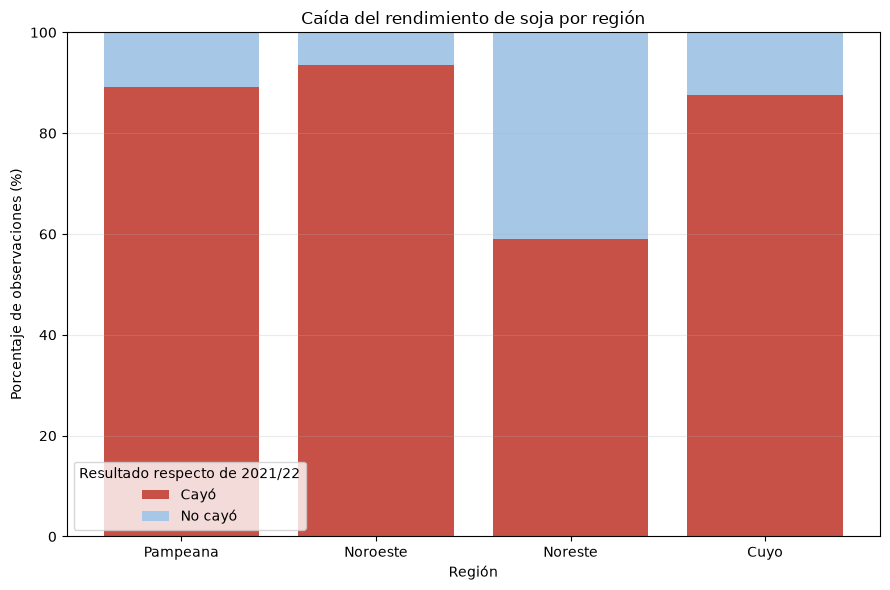

In [462]:
# Calcular los porcentajes de caída y no caída dentro de cada región
porcentajes_grafico_p6 = tabla_frecuencias_p6.div(
    tabla_frecuencias_p6.sum(axis=1), axis=0
) * 100

# Crear el gráfico de barras apiladas al 100 por ciento
figura_chi_p6, eje_chi_p6 = plt.subplots(figsize=(9, 6))
eje_chi_p6.bar(
    porcentajes_grafico_p6.index,
    porcentajes_grafico_p6["Cayó"],
    color="#C75146",
    label="Cayó"
)
eje_chi_p6.bar(
    porcentajes_grafico_p6.index,
    porcentajes_grafico_p6["No cayó"],
    bottom=porcentajes_grafico_p6["Cayó"],
    color="#A7C7E7",
    label="No cayó"
)
eje_chi_p6.set_title("Caída del rendimiento de soja por región")
eje_chi_p6.set_xlabel("Región")
eje_chi_p6.set_ylabel("Porcentaje de observaciones (%)")
eje_chi_p6.set_ylim(0, 100)
eje_chi_p6.legend(title="Resultado respecto de 2021/22")
eje_chi_p6.grid(axis="y", alpha=0.25)
figura_chi_p6.tight_layout()
plt.show()


### Interpretación del gráfico de barras apiladas

El gráfico confirma visualmente que la proporción de caídas es mayor en Noroeste y Pampeana que en Noreste. Cuyo presenta un porcentaje alto de caídas, pero se basa en solo 8 observaciones, por lo que su barra debe interpretarse con cautela.

La figura describe diferencias en la distribución observada; no identifica causas de la caída ni permite afirmar que las regiones produzcan efectos sobre el rendimiento.


### Síntesis del Punto 6

La tabla de contingencia descriptiva incluyó 276 observaciones válidas de soja distribuidas en Pampeana, Noroeste, Noreste y Cuyo. Para el contraste se excluyó Cuyo por contar con solo 8 observaciones y se utilizaron las otras tres regiones.

El test chi-cuadrado sobre Pampeana, Noroeste y Noreste produjo χ²(2) = 27,7289 y p < 0,001. Las frecuencias esperadas cumplieron el mínimo de 5, por lo que se rechazó H0 al 5 %.

Las conclusiones están limitadas por el tamaño reducido de Cuyo, la posible dependencia territorial entre departamentos y el carácter estimativo de la base. La asociación estadística no implica causalidad ni permite atribuir la caída a la sequía u otros factores no analizados.


# Punto 7 – Tests no paramétricos

Se compararán los rendimientos de soja de las campañas 2021/22 y 2022/23 para las mismas unidades territoriales. Se utilizará el test de Wilcoxon de rangos con signo para muestras apareadas.

Una prueba no paramétrica utiliza menos supuestos sobre la distribución de los valores que una prueba paramétrica. Wilcoxon analiza los rangos de las diferencias apareadas y no requiere normalidad de los valores originales. La interpretación habitual como contraste de localización requiere considerar la simetría de la distribución de las diferencias.


## Fundamento de la técnica y preparación de los datos

Las muestras son apareadas porque cada rendimiento de 2021/22 se vincula con el rendimiento de 2022/23 del mismo departamento y cultivo. Wilcoxon es apropiado para este diseño cuando se desea estudiar si las diferencias se centran en cero. Mann-Whitney compara dos grupos independientes y Kruskal-Wallis compara tres o más grupos independientes; no reemplazan automáticamente a Wilcoxon cuando las observaciones están apareadas.

La diferencia se define como rendimiento 2022/23 menos rendimiento 2021/22. Una diferencia positiva indica aumento, una negativa indica caída y una diferencia igual a cero indica ausencia de cambio. Los rendimientos iguales a cero se conservan y no se confunden con diferencias iguales a cero.


In [463]:
# Importar las herramientas necesarias para el análisis apareado
import scipy
from scipy import stats

# Seleccionar soja con las variables de ambas campañas y la unidad territorial
soja_pares_p7 = df.loc[
    df["cultivo"].eq("soja"),
    ["provincia", "region", "departamento", "cultivo", "rendimiento_kg_ha", "rendimiento_2021_22_kg_ha"]
].copy()
cantidad_inicial_p7 = len(soja_pares_p7)

# Conservar solamente los pares con información válida en ambas campañas
soja_pares_validos_p7 = soja_pares_p7.dropna(
    subset=["rendimiento_kg_ha", "rendimiento_2021_22_kg_ha"]
).copy()
cantidad_pares_p7 = len(soja_pares_validos_p7)
cantidad_excluidos_p7 = cantidad_inicial_p7 - cantidad_pares_p7
# Verificar que no haya duplicaciones de la unidad de observación
duplicados_unidad_p7 = soja_pares_validos_p7.duplicated(
    ["provincia", "region", "departamento", "cultivo"]
).sum()
# Calcular las diferencias entre las dos campañas
diferencias_p7 = (
    soja_pares_validos_p7["rendimiento_kg_ha"]
    - soja_pares_validos_p7["rendimiento_2021_22_kg_ha"]
)
cantidad_cero_p7 = int((diferencias_p7 == 0).sum())
cantidad_aumentos_p7 = int((diferencias_p7 > 0).sum())
cantidad_caidas_p7 = int((diferencias_p7 < 0).sum())

# Construir la tabla descriptiva de ambas campañas
tabla_campanas_p7 = pd.DataFrame({
    "Campaña": ["2021/22", "2022/23"],
    "Observaciones válidas": [cantidad_pares_p7, cantidad_pares_p7],
    "Media (kg/ha)": [soja_pares_validos_p7["rendimiento_2021_22_kg_ha"].mean(), soja_pares_validos_p7["rendimiento_kg_ha"].mean()],
    "Mediana (kg/ha)": [soja_pares_validos_p7["rendimiento_2021_22_kg_ha"].median(), soja_pares_validos_p7["rendimiento_kg_ha"].median()],
    "Desviación estándar (kg/ha)": [soja_pares_validos_p7["rendimiento_2021_22_kg_ha"].std(ddof=1), soja_pares_validos_p7["rendimiento_kg_ha"].std(ddof=1)],
    "Mínimo (kg/ha)": [soja_pares_validos_p7["rendimiento_2021_22_kg_ha"].min(), soja_pares_validos_p7["rendimiento_kg_ha"].min()],
    "Máximo (kg/ha)": [soja_pares_validos_p7["rendimiento_2021_22_kg_ha"].max(), soja_pares_validos_p7["rendimiento_kg_ha"].max()]
}).round(2)

# Resumir la dirección y magnitud descriptiva de las diferencias
tabla_diferencias_p7 = pd.DataFrame({
    "Medida": ["Media de diferencias (kg/ha)", "Mediana de diferencias (kg/ha)", "Desviación estándar (kg/ha)", "Aumentos (%)", "Caídas (%)", "Sin cambios (%)"],
    "Resultado": [diferencias_p7.mean(), diferencias_p7.median(), diferencias_p7.std(ddof=1), cantidad_aumentos_p7 / cantidad_pares_p7 * 100, cantidad_caidas_p7 / cantidad_pares_p7 * 100, cantidad_cero_p7 / cantidad_pares_p7 * 100]
}).round(2)
display(tabla_campanas_p7)
display(tabla_diferencias_p7)


,Campaña,Observaciones válidas,Media (kg/ha),Mediana (kg/ha),Desviación estándar (kg/ha),Mínimo (kg/ha),Máximo (kg/ha)
0,2021/22,276,2431.72,2500.0,598.59,700.0,3658.0
1,2022/23,276,1692.71,1587.5,484.95,0.0,3147.0


,Medida,Resultado
0,Media de diferencias (kg/ha),-739.01
1,Mediana de diferencias (kg/ha),-874.50
2,Desviación estándar (kg/ha),700.69
3,Aumentos (%),11.23
4,Caídas (%),85.87
5,Sin cambios (%),2.90


### Interpretación de las estadísticas descriptivas

Se analizaron 276 pares completos de los 281 registros iniciales de soja; se excluyeron 5 por falta de información en alguna campaña. No se detectaron duplicaciones de la unidad territorial. El rendimiento medio disminuyó de 2.431,72 kg/ha en 2021/22 a 1.692,71 kg/ha en 2022/23, mientras que las medianas fueron 2.500 y 1.587,50 kg/ha.

La diferencia media fue −739,01 kg/ha y la mediana −874,50 kg/ha. Hubo 237 caídas (85,87 %), 31 aumentos (11,23 %) y 8 diferencias iguales a cero (2,90 %). Estas medidas son promedios de diferencias departamentales y no representan necesariamente una variación del rendimiento agregado nacional.


## Visualización de las diferencias apareadas

El histograma de diferencias permite observar su concentración, dispersión y posible asimetría. La línea vertical en cero separa aumentos de caídas. El boxplot compara las distribuciones marginales de ambas campañas, pero no muestra por sí solo qué observaciones forman cada par; esa estructura se conserva en el cálculo de las diferencias.


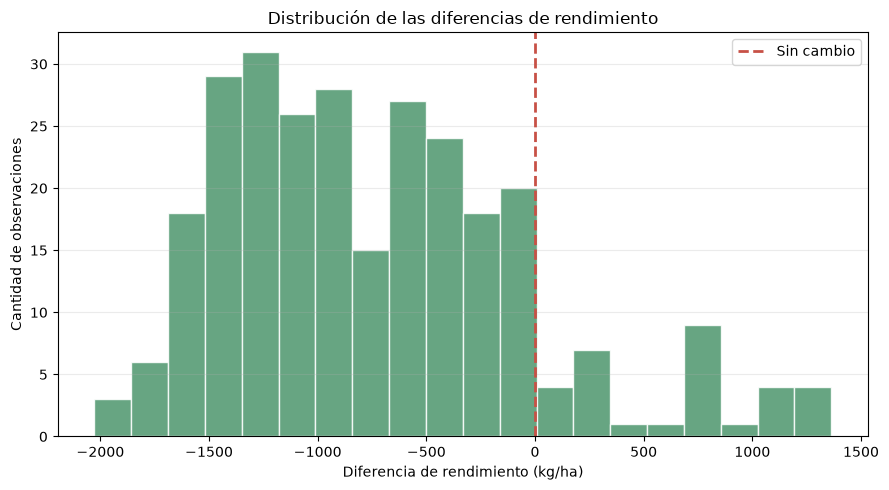

In [464]:
# Crear el histograma de las diferencias entre campañas
figura_diferencias_p7, eje_diferencias_p7 = plt.subplots(figsize=(9, 5))
eje_diferencias_p7.hist(
    diferencias_p7,
    bins=20,
    color="#4C956C",
    edgecolor="white",
    alpha=0.85
)
eje_diferencias_p7.axvline(0, color="#C75146", linestyle="--", linewidth=2, label="Sin cambio")
eje_diferencias_p7.set_title("Distribución de las diferencias de rendimiento")
eje_diferencias_p7.set_xlabel("Diferencia de rendimiento (kg/ha)")
eje_diferencias_p7.set_ylabel("Cantidad de observaciones")
eje_diferencias_p7.legend()
eje_diferencias_p7.grid(axis="y", alpha=0.25)
figura_diferencias_p7.tight_layout()
plt.show()


### Interpretación del histograma de diferencias

La mayor parte de las diferencias se ubica a la izquierda de cero, en concordancia con las 237 caídas observadas. La distribución presenta dispersión amplia, con diferencias entre −2.027 y 1.363 kg/ha, y asimetría positiva de aproximadamente 0,844. La forma observada no respalda una simetría clara, lo que limita la interpretación del test de Wilcoxon como contraste de una diferencia de localización simple.


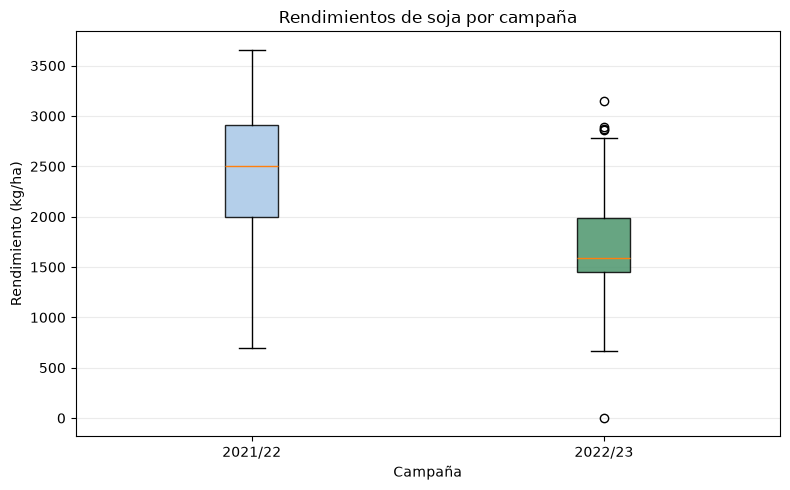

In [465]:
# Preparar los rendimientos apareados para comparar sus distribuciones marginales
rendimientos_boxplot_p7 = [
    soja_pares_validos_p7["rendimiento_2021_22_kg_ha"],
    soja_pares_validos_p7["rendimiento_kg_ha"]
]

# Crear el boxplot comparativo y conservar los posibles valores extremos
figura_boxplot_p7, eje_boxplot_p7 = plt.subplots(figsize=(8, 5))
cajas_p7 = eje_boxplot_p7.boxplot(
    rendimientos_boxplot_p7,
    tick_labels=["2021/22", "2022/23"],
    patch_artist=True,
    showfliers=True,
    whis=1.5
)
for caja, color in zip(cajas_p7["boxes"], ["#A7C7E7", "#4C956C"]):
    caja.set_facecolor(color)
    caja.set_alpha(0.85)
eje_boxplot_p7.set_title("Rendimientos de soja por campaña")
eje_boxplot_p7.set_xlabel("Campaña")
eje_boxplot_p7.set_ylabel("Rendimiento (kg/ha)")
eje_boxplot_p7.grid(axis="y", alpha=0.25)
figura_boxplot_p7.tight_layout()
plt.show()


### Interpretación del boxplot comparativo

El boxplot muestra un desplazamiento general hacia valores menores en 2022/23 respecto de 2021/22, coherente con la reducción de las medias y medianas. También permite observar dispersión y posibles valores extremos en cada campaña. Esta comparación es marginal: el test inferencial utiliza las diferencias de cada par y no trata las campañas como muestras independientes.


## Supuestos e hipótesis del test

El test requiere pares correctamente definidos, independencia entre pares y una distribución de diferencias aproximadamente simétrica si se interpreta como contraste de localización. Las diferencias iguales a cero generan empates y se excluyen del cálculo de rangos cuando se utiliza zero_method = wilcox; no se eliminan del conjunto de datos ni de las estadísticas descriptivas.

H0: la distribución de las diferencias está centrada en cero. H1: la distribución de las diferencias no está centrada en cero. Se utilizará un contraste bilateral con α = 0,05. Estas hipótesis no se formulan como igualdad de medias poblacionales.


In [466]:
# Aplicar Wilcoxon bilateral sobre los pares válidos
# zero_method='wilcox' excluye las diferencias cero del cálculo de rangos
# method='approx' utiliza una aproximación asintótica por el tamaño muestral y los empates
resultado_wilcoxon_p7 = stats.wilcoxon(
    soja_pares_validos_p7["rendimiento_kg_ha"],
    soja_pares_validos_p7["rendimiento_2021_22_kg_ha"],
    zero_method="wilcox",
    alternative="two-sided",
    method="approx"
)
cantidad_no_nulas_p7 = cantidad_aumentos_p7 + cantidad_caidas_p7
alfa_p7 = 0.05
decision_wilcoxon_p7 = (
    "Rechazar H0" if resultado_wilcoxon_p7.pvalue < alfa_p7 else "No rechazar H0"
)

tabla_wilcoxon_p7 = pd.DataFrame({
    "Pares completos": [cantidad_pares_p7],
    "Diferencias no nulas": [cantidad_no_nulas_p7],
    "Diferencias cero": [cantidad_cero_p7],
    "Estadístico W": [resultado_wilcoxon_p7.statistic],
    "Valor p aproximado": [resultado_wilcoxon_p7.pvalue],
    "Alfa": [alfa_p7],
    "Decisión": [decision_wilcoxon_p7]
}).round(6)
tabla_wilcoxon_p7["Valor p aproximado"] = tabla_wilcoxon_p7["Valor p aproximado"].map(lambda valor: "<0,001" if valor < 0.001 else f"{valor:.4f}")
display(tabla_wilcoxon_p7)


,Pares completos,Diferencias no nulas,Diferencias cero,Estadístico W,Valor p aproximado,Alfa,Decisión
0,276,268,8,2900.0,"<0,001",0.05,Rechazar H0


### Interpretación del test de Wilcoxon

El test se aplicó sobre 276 pares completos; 268 diferencias fueron no nulas y 8 fueron iguales a cero. Con zero_method = wilcox, el estadístico fue W = 2.900 y el valor p aproximado fue 1,08 × 10⁻³². Por lo tanto, con α = 0,05 se rechaza H0: existe evidencia de que la distribución de las diferencias no está centrada en cero.

La mediana de las diferencias fue −874,50 kg/ha y la proporción de caídas fue 85,87 %, lo que indica que el desplazamiento observado se orienta principalmente hacia una disminución. La presencia de empates y la posible asimetría aconsejan interpretar el resultado como evidencia sobre la posición de las diferencias, sin equipararlo automáticamente a una diferencia de medias. El valor p es aproximado y no demuestra igualdad ni causalidad.


### Síntesis del Punto 7

El test de Wilcoxon evidenció una diferencia sistemática entre los rendimientos de soja de ambas campañas en los pares disponibles. La presencia de empates y la posible dependencia territorial limitan el alcance de la inferencia, que no debe interpretarse como evidencia de causalidad.
